# Tratamiento de datos · Desnutrición crónica infantil (ENDES 2025)
**Curso:** Inteligencia Artificial I (IS-484) · Escuela Profesional de Ingeniería de Sistemas · UNSCH
**Proyecto:** predicción de la desnutrición crónica infantil con XGBoost, usando datos públicos reales del INEI.

Este cuaderno resume, **en orden**, cómo se trataron los datos: desde los módulos descargados hasta un dataset limpio listo para entrenar. Cada sección tiene: **qué se hizo**, **por qué** y **una evidencia** (gráfico o tabla) con su lectura.

### Recorrido
| # | Etapa | Pregunta que responde | Guía |
|---|---|---|---|
| 1 | Problema y datos | ¿Qué se predice y con qué? | S03 |
| 2 | Integración de módulos | ¿Cómo se juntaron las tablas y qué variables se eligieron? | S04 |
| 3 | Diagnóstico del dato crudo | ¿Qué problemas tienen los datos? | S03-S04 |
| 4 | Limpieza paso a paso (+ tablas de técnicas y estadísticos) | ¿Cómo se corrigieron y con qué números? | S04 |
| 5 | Antes vs. después | ¿Cuánto cambió? | S04 |
| 6 | Exploración con datos limpios | ¿Qué relaciones aparecen ya sin ruido? | S03, S05 |
| 7 | Modelos de base | ¿Mejoró el rendimiento? | S03, S05 |
| 8 | Conclusiones y archivos | ¿Qué queda listo? | — |

**Archivos del proyecto:** `dataset_integrado_crudo.csv` (crudo, se conserva) → `dataset_limpio.csv` (resultado).

In [1]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook", font_scale=0.95)
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 11})
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 70)
AZUL, NARANJA, ROJO, GRIS, VERDE = "#4C78A8", "#F58518", "#E45756", "#9D9D9D", "#54A24B"


def nota(texto):
    display(Markdown(texto))


RAIZ = Path.cwd().parent if Path.cwd().name == "2 notebooks" else Path.cwd()
SALIDA = RAIZ / "3 datos_procesados"
crudo = pd.read_csv(SALIDA / "dataset_integrado_crudo.csv", dtype={"caseid": str, "hhid": str})
limpio = pd.read_csv(SALIDA / "dataset_limpio.csv", dtype={"caseid": str, "hhid": str})
dic_c = pd.read_csv(SALIDA / "diccionario_variables.csv")
dic_l = pd.read_csv(SALIDA / "diccionario_limpio.csv")
log = pd.read_csv(SALIDA / "registro_limpieza.csv")

FEAT_C = dic_c.loc[dic_c.rol == "feature", "nombre"].tolist()
CATEG_C = dic_c.loc[(dic_c.rol == "feature") & (dic_c.tipo == "categórica"), "nombre"].tolist()
FEAT_L = dic_l.loc[dic_l.rol == "feature", "nombre"].tolist()
CATEG_L = dic_l.loc[(dic_l.rol == "feature") & (dic_l.tipo == "categórica"), "nombre"].tolist()
CODIGOS = {r.nombre: [int(float(x)) for x in str(r.codigos_a_nan).split(",") if x.strip()]
           for r in dic_c.itertuples() if isinstance(r.codigos_a_nan, str) and r.codigos_a_nan.strip()}

crudo_ok = crudo[crudo["haz"].notna()].reset_index(drop=True)        # mismos niños que el limpio
assert (crudo_ok["caseid"] == limpio["caseid"]).all() and len(crudo_ok) == len(limpio)
PREV = limpio["desnutricion_cronica"].mean() * 100
print(f"Crudo: {crudo.shape[0]:,} × {crudo.shape[1]} | Limpio: {limpio.shape[0]:,} × {limpio.shape[1]} | prevalencia: {PREV:.1f} %")

Crudo: 18,841 × 50 | Limpio: 18,023 × 49 | prevalencia: 11.9 %


## 1. El problema y los datos
- **Fuente:** ENDES 2025 (Encuesta Demográfica y de Salud Familiar, INEI), módulos de hogar, vivienda, salud, embarazo, anemia y programas sociales.
- **Unidad de análisis:** un niño menor de 5 años con talla medida.
- **Objetivo (dos formulaciones sobre los mismos datos):**

| Objetivo | Tipo de problema | Definición |
|---|---|---|
| `desnutricion_cronica` | **Clasificación** (se usará XGBoost) | 1 si el puntaje Z de talla para la edad (`haz`) es menor que −2 (patrón OMS) |
| `haz` | **Regresión** (Semana 05) | el puntaje Z continuo |

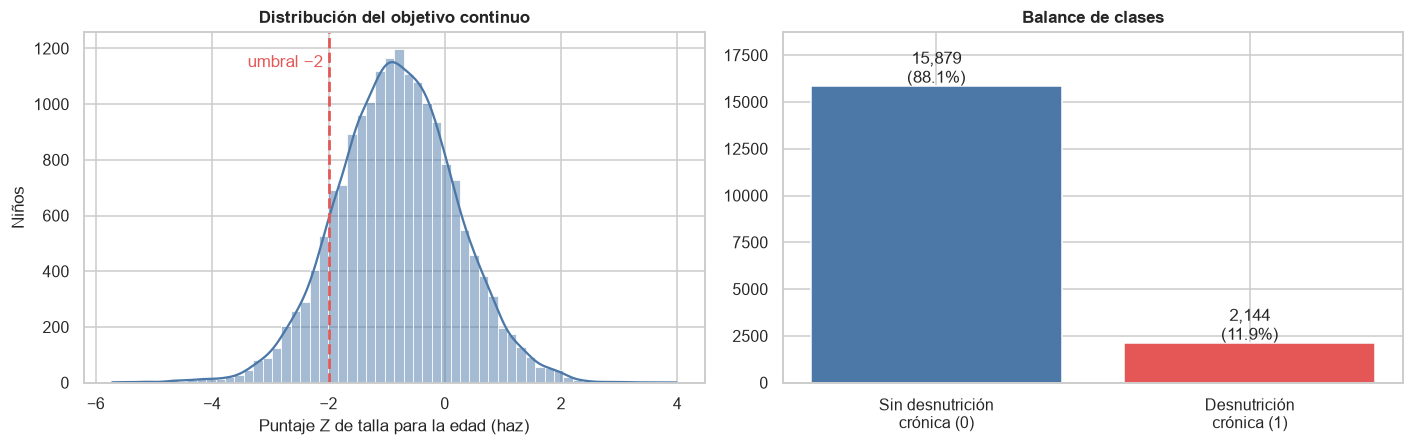

**Qué muestra:** izquierda, el puntaje Z (los niños a la izquierda de la línea roja están desnutridos); derecha, cuántos niños hay en cada clase.  
**Lectura:** 18,023 niños con objetivo válido; **11.9 %** con desnutrición crónica: un problema **desbalanceado** (1 de cada 8). Por eso no se usará la exactitud como métrica, sino AUC-PR, recall y F1, con `scale_pos_weight` en XGBoost.

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
sns.histplot(limpio["haz"], bins=60, kde=True, color=AZUL, ax=axes[0])
axes[0].axvline(-2, color=ROJO, ls="--", lw=1.8)
axes[0].text(-2.1, axes[0].get_ylim()[1] * 0.9, "umbral −2", color=ROJO, ha="right")
axes[0].set_xlabel("Puntaje Z de talla para la edad (haz)")
axes[0].set_ylabel("Niños")
axes[0].set_title("Distribución del objetivo continuo")
conteo = limpio["desnutricion_cronica"].value_counts().sort_index()
b = axes[1].bar(["Sin desnutrición\ncrónica (0)", "Desnutrición\ncrónica (1)"], conteo.values, color=[AZUL, ROJO])
for r, v in zip(b, conteo.values):
    axes[1].text(r.get_x() + r.get_width() / 2, v + 150, f"{v:,}\n({100 * v / len(limpio):.1f}%)", ha="center")
axes[1].set_ylim(0, conteo.max() * 1.18)
axes[1].set_title("Balance de clases")
plt.tight_layout()
plt.show()
nota(f"**Qué muestra:** izquierda, el puntaje Z (los niños a la izquierda de la línea roja están desnutridos); derecha, cuántos niños hay en cada clase.  \n"
     f"**Lectura:** {len(limpio):,} niños con objetivo válido; **{PREV:.1f} %** con desnutrición crónica: un problema **desbalanceado** (1 de cada 8). Por eso no se usará la exactitud como métrica, sino AUC-PR, recall y F1, con `scale_pos_weight` en XGBoost.")

## 2. Integración de módulos y selección de variables (notebook 01)
**Qué se hizo:** de **27 tablas** descargadas (más de 2 600 columnas) se eligieron **15 tablas** y **42 variables candidatas**, y se cruzaron por sus llaves hasta tener **una fila por niño** (`CASEID + índice del niño` para el niño; `HHID` para el hogar; línea de la madre para sus medidas).

**Criterios:** (1) factor conocido de la desnutrición crónica (OMS, UNICEF, ENDES); (2) disponible para casi todos los niños; (3) **sin fuga de datos**: no entran el peso, la talla ni las demás medidas del niño con las que se calcula el puntaje Z.

**Regla de oro de cada cruce:** la tabla base nunca cambia de tamaño (siempre 18 841 filas) y se informa el % de niños que encontró pareja.

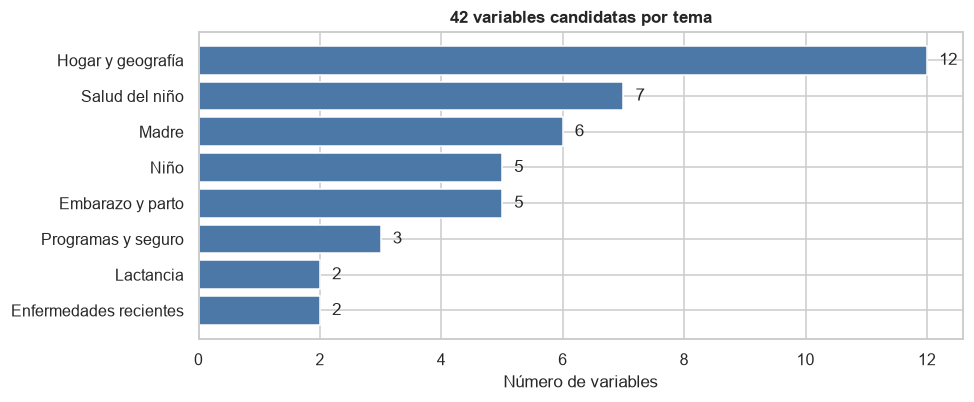

,n,variables
bloque,,
Niño,5,"edad_meses, sexo_nino, orden_nacimiento, intervalo_nac_previo_mese..."
Embarazo y parto,5,"peso_nacer_g, visitas_prenatales, hierro_embarazo, tamano_percibid..."
Lactancia,2,"meses_lactancia, lactancia_exclusiva_6m"
Enfermedades recientes,2,"diarrea_2sem, tos_2sem"
Salud del niño,7,"n_controles_cred, hierro_jarabe_7d, micronutrientes_polvo_7d, anti..."
Madre,6,"edad_madre, edad_primer_parto, nivel_educativo_madre, lengua_mater..."
Hogar y geografía,12,"quintil_riqueza, area_residencia, departamento, region_natural, al..."
Programas y seguro,3,"hogar_juntos, hogar_vaso_leche, seguro_nino_sis"


In [3]:
feat = dic_c[dic_c.rol == "feature"]
por_bloque = feat.groupby("bloque", sort=False).nombre.agg(n="count", variables=lambda s: ", ".join(s.iloc[:5]) + (" …" if len(s) > 5 else ""))

fig, ax = plt.subplots(figsize=(9, 3.8))
orden = por_bloque["n"].sort_values()
ax.barh(orden.index, orden.values, color=AZUL)
for i, v in enumerate(orden.values):
    ax.text(v + 0.2, i, str(v), va="center")
ax.set_xlabel("Número de variables")
ax.set_title("42 variables candidatas por tema")
plt.tight_layout()
plt.show()
por_bloque

**Qué muestra:** cuántas variables aporta cada tema y cuáles son.  
**Lectura:** el modelo mira al **niño** y su **nacimiento**, la **madre**, la **salud y suplementación**, el **hogar y entorno** (agua, saneamiento, altitud) y el **apoyo social**; es decir, los factores que la literatura asocia a la desnutrición crónica.

## 3. Diagnóstico del dato crudo (notebook 02)
Antes de limpiar se diagnosticó el dataset **sin modificarlo**. Cuatro hallazgos explican todo el tratamiento posterior.

### 3.1 Valores vacíos: muchos son "por diseño"

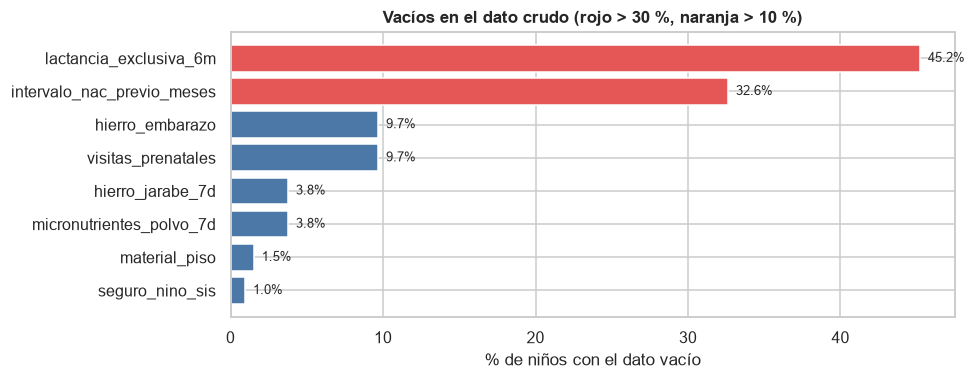

In [4]:
vac_c = crudo_ok[FEAT_C].isna().mean().mul(100).sort_values(ascending=False)
vac_c = vac_c[vac_c > 0]
fig, ax = plt.subplots(figsize=(9, 0.3 * len(vac_c) + 1.2))
ax.barh(vac_c.index[::-1], vac_c.values[::-1], color=[ROJO if v > 30 else NARANJA if v > 10 else AZUL for v in vac_c.values[::-1]])
for i, v in enumerate(vac_c.values[::-1]):
    ax.text(v + 0.5, i, f"{v:.1f}%", va="center", fontsize=8.5)
ax.set_xlabel("% de niños con el dato vacío")
ax.set_title("Vacíos en el dato crudo (rojo > 30 %, naranja > 10 %)")
plt.tight_layout()
plt.show()

**Qué muestra:** el % de niños sin dato en cada variable.  
**Lectura:** 25 de 42 variables están completas. Los vacíos altos **no son errores**: la lactancia exclusiva solo aplica desde los 6 meses; el intervalo entre hijos está vacío en los primogénitos; las visitas prenatales y el hierro del embarazo solo se preguntan por el **hijo menor** de cada madre.

### 3.2 Códigos especiales: el problema más importante
ENDES guarda los "no sabe / no se pesó / no se pudo medir" como **números** (9996, 9998, 9999, 98, 9, 8). Si no se convierten en vacío, el modelo los toma como cantidades reales.

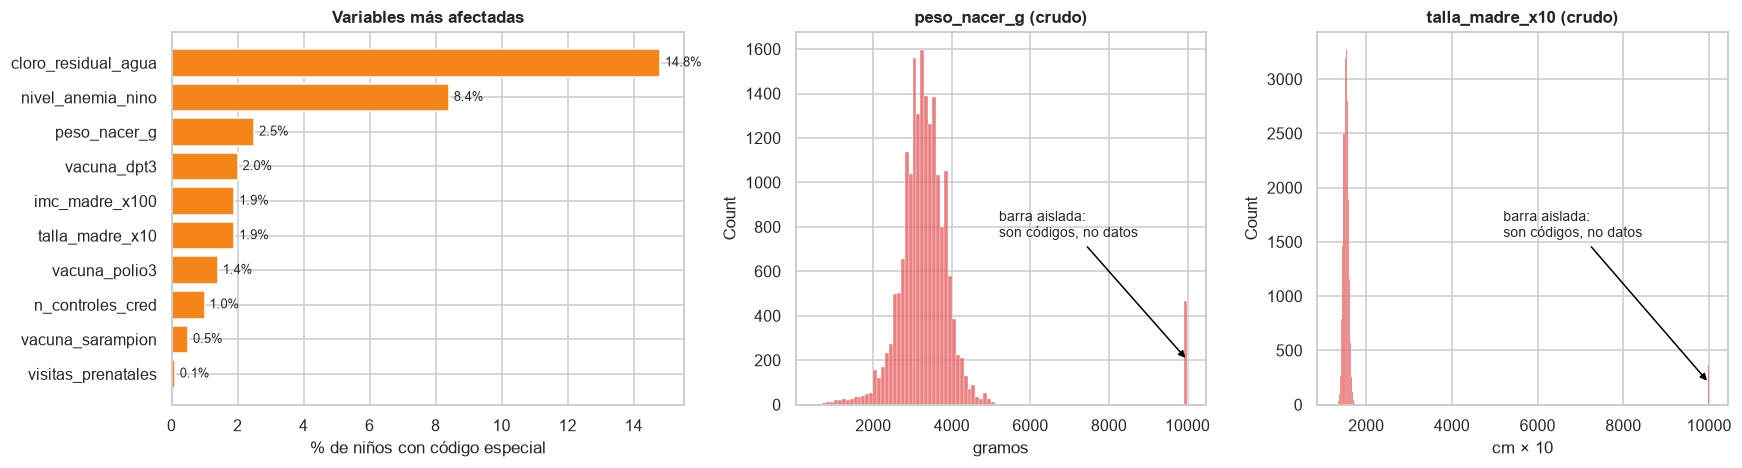

**Qué muestra:** izquierda, qué variables tienen más códigos; centro y derecha, el efecto en el peso al nacer y la talla de la madre.  
**Lectura:** 20 variables llevan códigos (6,561 valores). En los histogramas se ve una barra suelta en 9 998-9 999 que estira la escala y distorsiona medias, correlaciones y modelos. Además, `cloro_residual_agua` trae un **código 6 que no figura en el diccionario del INEI**.

In [5]:
filas = [{"variable": v, "n": int(crudo[v].isin(c).sum())} for v, c in CODIGOS.items()]
cod = pd.DataFrame(filas).query("n > 0").sort_values("n", ascending=False)
cod["%"] = (100 * cod["n"] / len(crudo)).round(1)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4), gridspec_kw={"width_ratios": [1.25, 1, 1]})
top = cod.head(10)
axes[0].barh(top["variable"][::-1], top["%"][::-1], color=NARANJA)
for i, v in enumerate(top["%"][::-1]):
    axes[0].text(v + 0.15, i, f"{v}%", va="center", fontsize=8.5)
axes[0].set_xlabel("% de niños con código especial")
axes[0].set_title("Variables más afectadas")
for ax, var, ancho, unidad in zip(axes[1:], ["peso_nacer_g", "talla_madre_x10"], [100, 25], ["gramos", "cm × 10"]):
    sns.histplot(crudo[var].dropna(), binwidth=ancho, color=ROJO, ax=ax)
    ax.set_title(f"{var} (crudo)")
    ax.set_xlabel(unidad)
    ax.annotate("barra aislada:\nson códigos, no datos", xy=(9998, 200), xytext=(5200, ax.get_ylim()[1] * 0.45), arrowprops={"arrowstyle": "-|>", "color": "black"}, fontsize=9)
plt.tight_layout()
plt.show()
nota(f"**Qué muestra:** izquierda, qué variables tienen más códigos; centro y derecha, el efecto en el peso al nacer y la talla de la madre.  \n"
     f"**Lectura:** {len(cod)} variables llevan códigos ({int(cod['n'].sum()):,} valores). En los histogramas se ve una barra suelta en 9 998-9 999 que estira la escala y distorsiona medias, correlaciones y modelos. "
     f"Además, `cloro_residual_agua` trae un **código 6 que no figura en el diccionario del INEI**.")

### 3.3 Otros diagnósticos

In [6]:
dup = int(crudo.duplicated().sum())
madres = crudo["caseid"].nunique()
reglas_n = {
    "Filas duplicadas": dup,
    "Niños sin puntaje Z válido": int(crudo["haz"].isna().sum()),
    "Madres con más de un niño (hermanos)": int(len(crudo) - madres),
    "IMC de la madre fuera de 12-50 (sin códigos)": int((~crudo_ok.imc_madre_x100.between(1200, 5000) & ~crudo_ok.imc_madre_x100.isin([9998, 9999])).sum()),
    "Lactancia mayor que la edad del niño (sin 94/98)": int(((crudo_ok.meses_lactancia > crudo_ok.edad_meses) & ~crudo_ok.meses_lactancia.isin([94, 98])).sum()),
    "Códigos fuera del diccionario (cloro = 6)": int((crudo_ok.cloro_residual_agua == 6).sum()),
}
pd.Series(reglas_n, name="casos").to_frame()

,casos
Filas duplicadas,0
Niños sin puntaje Z válido,818
Madres con más de un niño (hermanos),1908
IMC de la madre fuera de 12-50 (sin códigos),18
Lactancia mayor que la edad del niño (sin 94/98),3
Códigos fuera del diccionario (cloro = 6),1155


**Lectura:** no hay duplicados y casi no hay incoherencias lógicas; los problemas reales son los **códigos**, los **vacíos por diseño**, los **818 niños sin objetivo** y la **estructura de grupo** (hermanos y niños del mismo conglomerado no son independientes, por lo que la división train/test se hace por conglomerado).

### 3.4 ¿Quiénes están más afectados? (la señal que el modelo debe aprender)

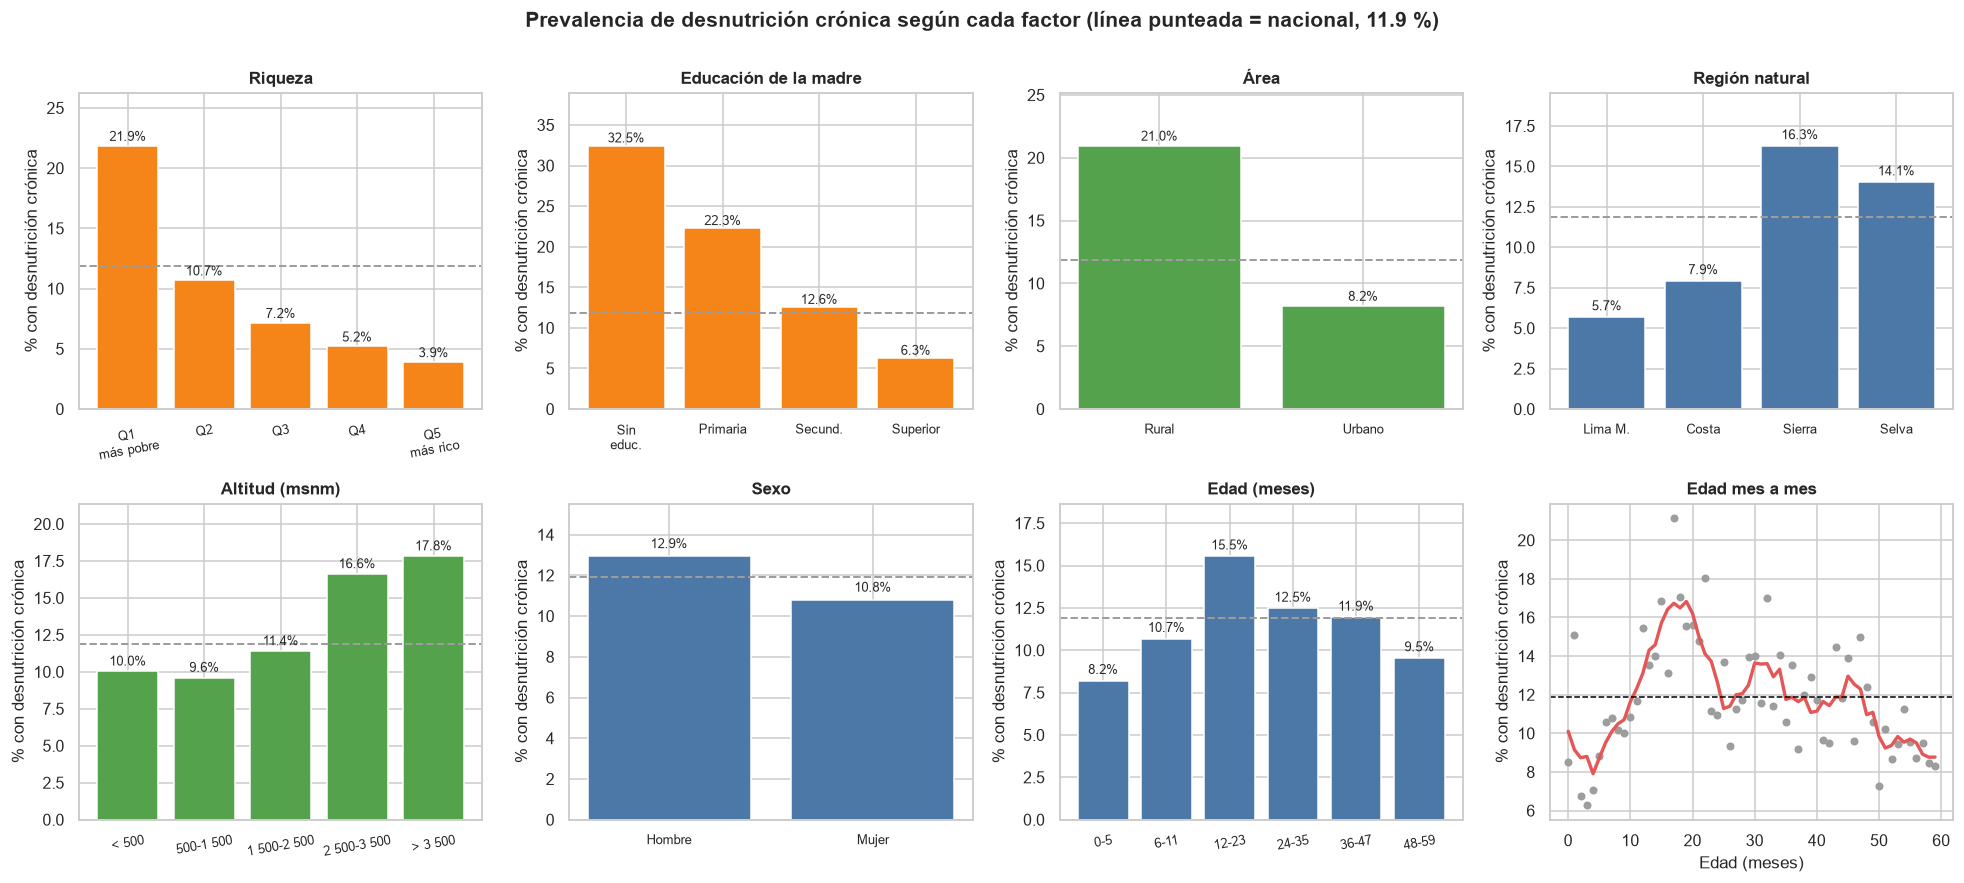

In [7]:
ETQ = {
    "quintil_riqueza": {1: "Q1\nmás pobre", 2: "Q2", 3: "Q3", 4: "Q4", 5: "Q5\nmás rico"},
    "nivel_educativo_madre": {0: "Sin\neduc.", 1: "Primaria", 2: "Secund.", 3: "Superior"},
    "region_natural": {1: "Lima M.", 2: "Costa", 3: "Sierra", 4: "Selva"},
}
alt = pd.cut(limpio["altitud_msnm"], [0, 500, 1500, 2500, 3500, 5000], labels=["< 500", "500-1 500", "1 500-2 500", "2 500-3 500", "> 3 500"])
edad = pd.cut(limpio["edad_meses"], [-1, 5, 11, 23, 35, 47, 59], labels=["0-5", "6-11", "12-23", "24-35", "36-47", "48-59"])
sexo = limpio["nino_mujer"].map({0: "Hombre", 1: "Mujer"})
area = limpio["area_rural"].map({0: "Urbano", 1: "Rural"})
paneles = [("Riqueza", limpio["quintil_riqueza"], ETQ["quintil_riqueza"], NARANJA), ("Educación de la madre", limpio["nivel_educativo_madre"], ETQ["nivel_educativo_madre"], NARANJA),
           ("Área", area, None, VERDE), ("Región natural", limpio["region_natural"], ETQ["region_natural"], AZUL),
           ("Altitud (msnm)", alt, None, VERDE), ("Sexo", sexo, None, AZUL), ("Edad (meses)", edad, None, AZUL)]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, (titulo, serie, etq, color) in zip(axes.ravel(), paneles):
    t = limpio.groupby(serie, observed=True)["desnutricion_cronica"].mean() * 100
    nombres = [etq.get(i, str(i)) for i in t.index] if etq else [str(i) for i in t.index]
    ax.bar(nombres, t.values, color=color)
    for i, m in enumerate(t.values):
        ax.text(i, m + 0.4, f"{m:.1f}%", ha="center", fontsize=8.5)
    ax.axhline(PREV, color=GRIS, ls="--", lw=1.3)
    ax.set_title(titulo)
    ax.set_ylabel("% con desnutrición crónica")
    ax.set_ylim(0, t.max() * 1.2)
    ax.tick_params(axis="x", labelsize=8.5, rotation=10 if len(nombres) > 4 else 0)
por_mes = limpio.groupby("edad_meses")["desnutricion_cronica"].mean().mul(100)
ax = axes[1, 3]
ax.scatter(por_mes.index, por_mes.values, s=18, color=GRIS)
ax.plot(por_mes.rolling(5, center=True, min_periods=1).mean(), color=ROJO, lw=2.2)
ax.axhline(PREV, color="black", ls="--", lw=1)
ax.set_xlabel("Edad (meses)")
ax.set_ylabel("% con desnutrición crónica")
ax.set_title("Edad mes a mes")
fig.suptitle(f"Prevalencia de desnutrición crónica según cada factor (línea punteada = nacional, {PREV:.1f} %)", fontweight="bold", y=1.0)
plt.tight_layout()
plt.show()

**Qué muestra:** cada barra es el % de niños desnutridos en ese grupo; la línea punteada es el promedio nacional.  
**Lectura:** la desnutrición crónica se concentra en la **pobreza** (Q1 ≈ 22 % frente a Q5 ≈ 4 %), la **baja educación materna** (≈ 32 % sin educación), el **área rural** (≈ 21 %), **Sierra y Selva** y sobre los **2 500 m**. La **edad no es lineal**: sube hasta los 12-23 meses (≈ 15 %) y luego baja; los árboles de XGBoost captan bien este tipo de relación.

## 4. Limpieza paso a paso (notebook 03)
Cada problema del diagnóstico tiene su tratamiento. El archivo crudo **no se modifica**; todo se hace sobre una copia y queda anotado en un registro.

| Paso | Problema detectado | Tratamiento | Resultado |
|---|---|---|---|
| 1 | 818 niños sin puntaje Z | Eliminarlos | 18 023 niños |
| 2 | Duplicados | Revisar | 0 (nada que quitar) |
| 3 | Códigos especiales (9996-9999, 98, 9, 8) | Convertir a `NaN` variable por variable | 5 237 valores |
| 3b | 94 = "nunca amamantó"; vacunas 1, 2, 3 = "sí" | 94 → 0 meses; vacunas a 0/1 | 106 y 3 variables |
| 4 | Incoherencias lógicas | Corregir lo imposible | 21 valores |
| 5 | Atípicos (RIC) | Revisar: son reales, **se conservan** | 0 eliminados |
| 6 | "No vacunado" en bebés que aún no tienen edad | `NaN` = "no corresponde" | 5 652 valores |
| 7 | Códigos arbitrarios (1 = sí / 2 = no…) | Binarias 0/1, ordinal en orden real, renombres | 8 variables |
| 8 | Vacíos | Distinguir "no aplica" de "falta"; se conservan como `NaN` | — |
| 9 | Riesgo de fuga | Partición train/test **por conglomerado** (80/20) | 14 421 / 3 602 |
| 10 | Imputación y escalado | Solo con *train* y solo donde hace falta | no se guardan |

A continuación, la evidencia de los pasos principales.

### Pasos 1 y 3: niños sin objetivo y códigos especiales → vacío

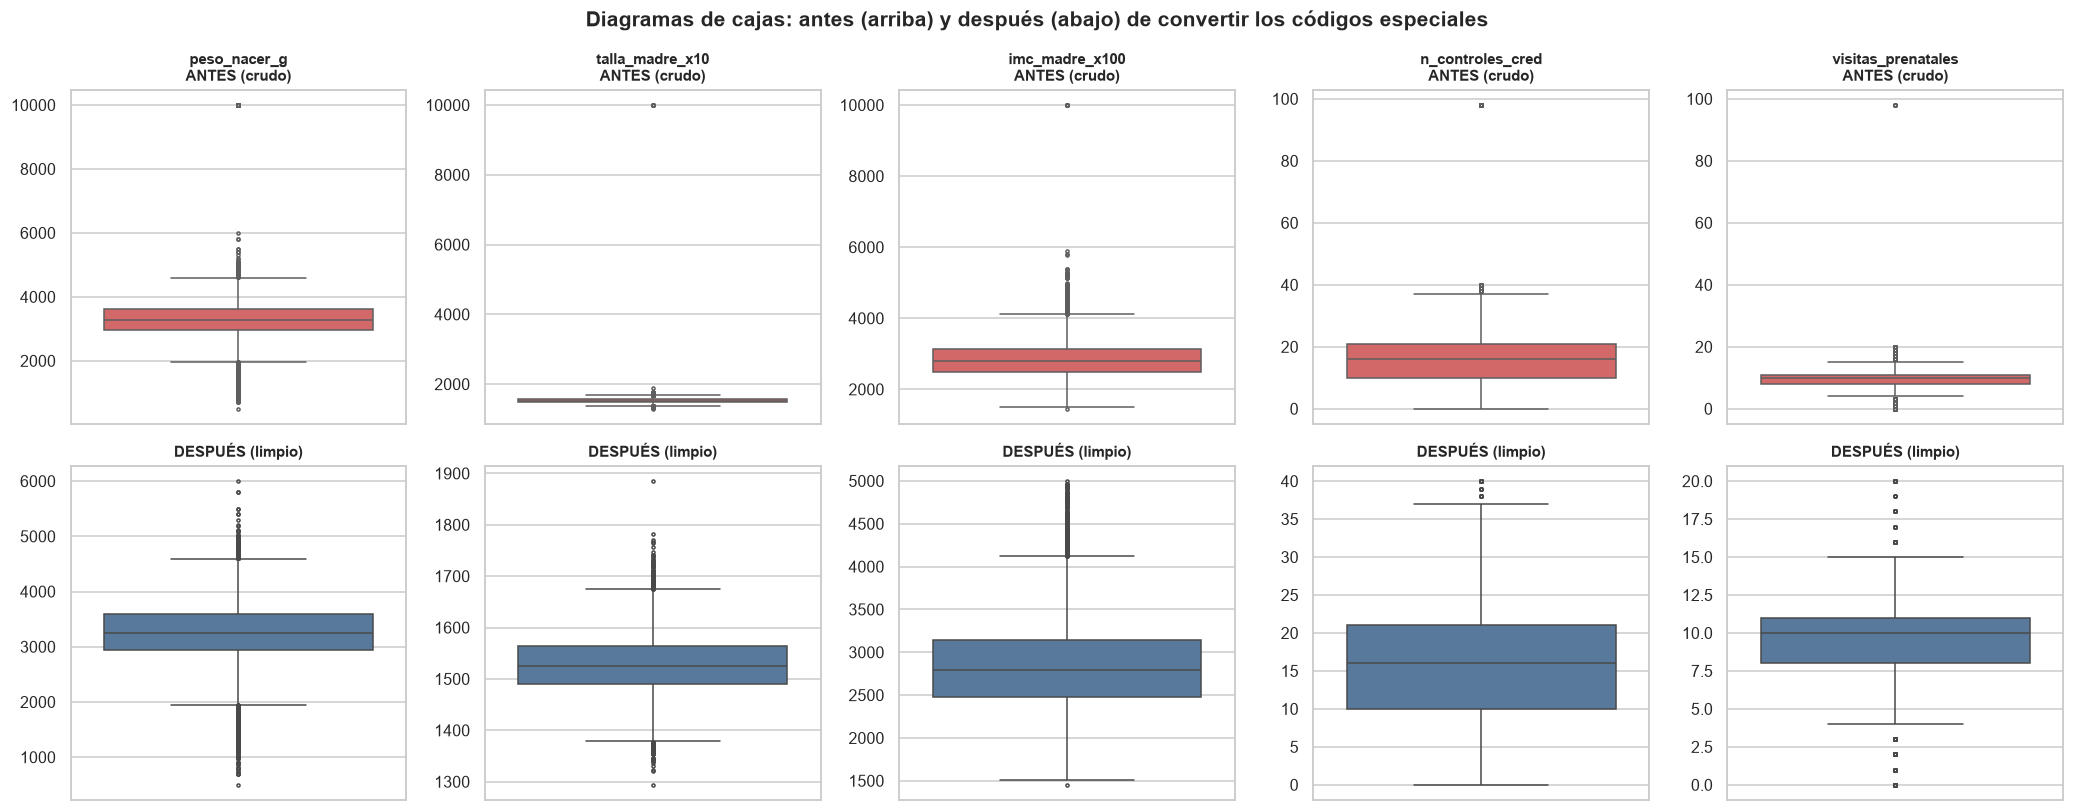

In [8]:
VARS = ["peso_nacer_g", "talla_madre_x10", "imc_madre_x100", "n_controles_cred", "visitas_prenatales"]
fig, axes = plt.subplots(2, 5, figsize=(19, 7.5))
for j, var in enumerate(VARS):
    sns.boxplot(y=crudo_ok[var], ax=axes[0, j], color=ROJO, fliersize=2)
    axes[0, j].set_title(f"{var}\nANTES (crudo)", fontsize=10)
    axes[0, j].set_ylabel("")
    sns.boxplot(y=limpio[var], ax=axes[1, j], color=AZUL, fliersize=2)
    axes[1, j].set_title("DESPUÉS (limpio)", fontsize=10)
    axes[1, j].set_ylabel("")
fig.suptitle("Diagramas de cajas: antes (arriba) y después (abajo) de convertir los códigos especiales", fontweight="bold")
plt.tight_layout()
plt.show()

**Cómo leerlo:** cada gráfico es una variable. La **caja** contiene al 50 % central de los niños, los **bigotes** llegan al dato normal más lejano y los **puntos** son valores atípicos.  
**Lectura:** arriba, los códigos (9 998, 9 999, 98) estiran la escala hasta 10 000 y la caja queda **aplastada**; abajo, sin ellos, la caja se ve completa y los valores son realistas (peso al nacer entre 500 y 6 000 g, talla materna entre 129 y 189 cm).

### Pasos 3b y 6: vacunas según la edad
Un bebé de 3 meses figura como "no vacunado" en DPT3 porque **aún no le toca**. Mezclar ambas cosas engaña al modelo, así que se deja `NaN` ("no corresponde") hasta la edad de la dosis (6 meses para DPT3 y polio; 12 para sarampión).

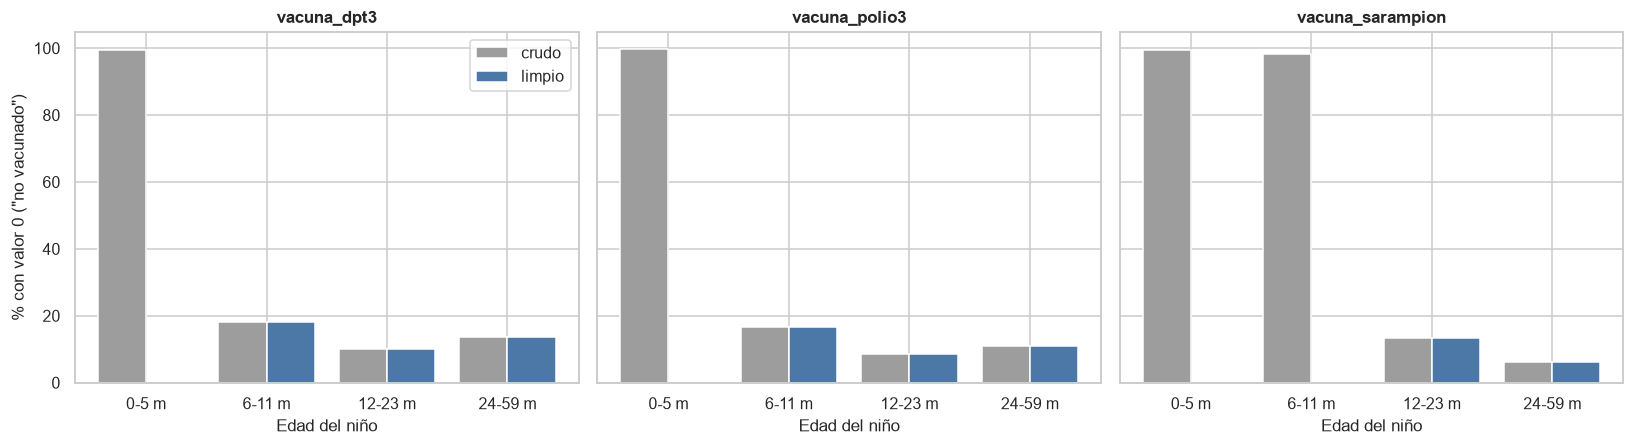

In [9]:
grupo = pd.cut(limpio["edad_meses"], [-1, 5, 11, 23, 59], labels=["0-5 m", "6-11 m", "12-23 m", "24-59 m"])
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, v in zip(axes, ["vacuna_dpt3", "vacuna_polio3", "vacuna_sarampion"]):
    antes = (crudo_ok[v] == 0).groupby(grupo, observed=True).mean() * 100
    despues = (limpio[v] == 0).groupby(grupo, observed=True).mean() * 100
    x = np.arange(4)
    ax.bar(x - 0.2, antes.values, width=0.4, color=GRIS, label="crudo")
    ax.bar(x + 0.2, despues.values, width=0.4, color=AZUL, label="limpio")
    ax.set_xticks(x)
    ax.set_xticklabels(antes.index)
    ax.set_title(v)
    ax.set_xlabel("Edad del niño")
axes[0].set_ylabel("% con valor 0 (\"no vacunado\")")
axes[0].legend()
plt.tight_layout()
plt.show()

**Cómo leerlo:** cada barra es el % de niños de ese tramo de edad con la vacuna en 0.  
**Lectura:** en el crudo, casi el 100 % de los bebés de 0-5 meses parecían "no vacunados"; tras la corrección esas barras desaparecen y las azules muestran la **cobertura real** (entre ≈ 6 % y 18 % sin vacunar).

### Paso 5: valores atípicos
Se aplicó el método del **rango intercuartílico (RIC)** sobre los datos ya sin códigos: es atípico lo que queda fuera de [Q1 − 1.5·RIC, Q3 + 1.5·RIC].

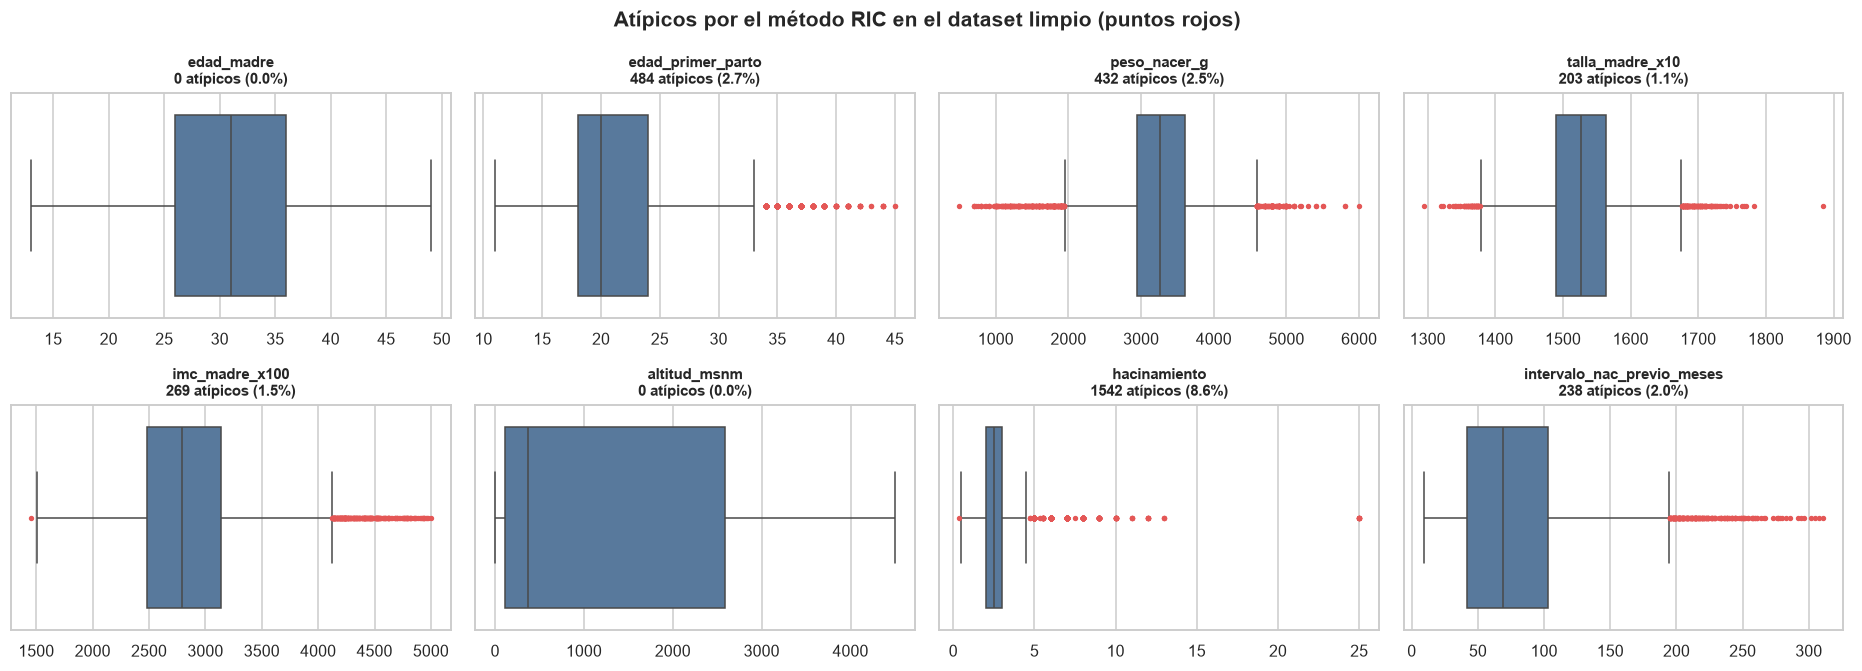

In [10]:
CONT = ["edad_madre", "edad_primer_parto", "peso_nacer_g", "talla_madre_x10", "imc_madre_x100", "altitud_msnm", "hacinamiento", "intervalo_nac_previo_meses"]
fig, axes = plt.subplots(2, 4, figsize=(17, 6.2))
for ax, var in zip(axes.ravel(), CONT):
    s = limpio[var].dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    n_out = int(((s < q1 - 1.5 * (q3 - q1)) | (s > q3 + 1.5 * (q3 - q1))).sum())
    sns.boxplot(x=limpio[var], ax=ax, color=AZUL, fliersize=2.5, flierprops={"markerfacecolor": ROJO, "markeredgecolor": ROJO})
    ax.set_title(f"{var}\n{n_out} atípicos ({100 * n_out / len(s):.1f}%)", fontsize=10)
    ax.set_xlabel("")
fig.suptitle("Atípicos por el método RIC en el dataset limpio (puntos rojos)", fontweight="bold")
plt.tight_layout()
plt.show()

**Lectura:** quedan pocos atípicos (0-9 % según la variable) y son **valores reales**: bebés muy grandes o muy pequeños, madres muy altas o bajas, familias numerosas. **Decisión: no eliminarlos.** Son justamente los casos de bajo peso al nacer o baja talla materna que más interesan, y los árboles no se afectan por extremos.

### Paso 8: qué vacíos quedan y por qué

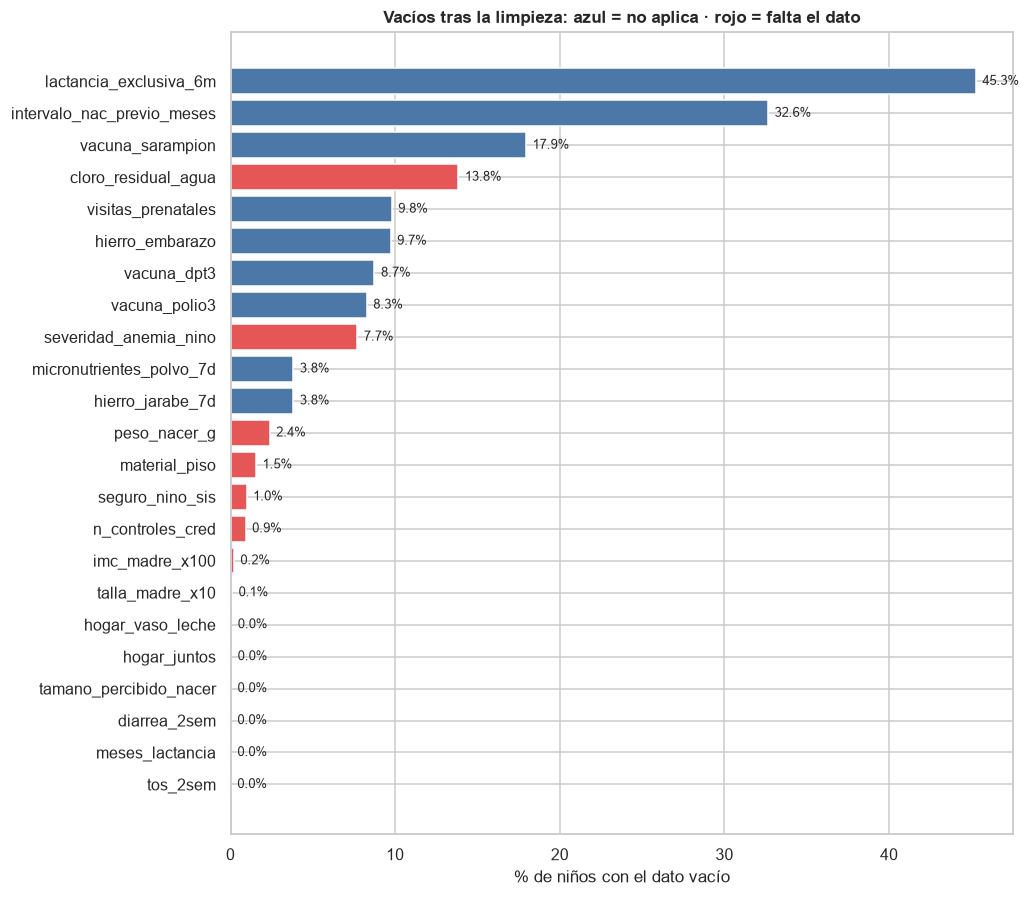

In [11]:
MOTIVO_NO_APLICA = {"lactancia_exclusiva_6m", "intervalo_nac_previo_meses", "visitas_prenatales", "hierro_embarazo", "hierro_jarabe_7d",
                    "micronutrientes_polvo_7d", "vacuna_dpt3", "vacuna_polio3", "vacuna_sarampion"}
vac_l = limpio[FEAT_L].isna().mean().mul(100)
vac_l = vac_l[vac_l > 0].sort_values()
fig, ax = plt.subplots(figsize=(9.5, 0.3 * len(vac_l) + 1.4))
ax.barh(vac_l.index, vac_l.values, color=[AZUL if v in MOTIVO_NO_APLICA else ROJO for v in vac_l.index])
for i, v in enumerate(vac_l.values):
    ax.text(v + 0.4, i, f"{v:.1f}%", va="center", fontsize=8.5)
ax.set_xlabel("% de niños con el dato vacío")
ax.set_title("Vacíos tras la limpieza: azul = no aplica · rojo = falta el dato")
plt.tight_layout()
plt.show()

**Lectura:** la mayoría de los vacíos (azul) son preguntas que **no aplican** a ese niño (primogénito, aún sin edad para la vacuna, pregunta solo del hijo menor): rellenarlos **inventaría información**, por eso se conservan como `NaN` (XGBoost los maneja). Los rojos (cloro, anemia no medida, peso, IMC…) son pocos y pequeños.

### Paso 7: codificación de variables
Un número solo es una **escala** si de verdad se ordena. Por eso cada tipo recibe un tratamiento distinto:

In [12]:
pd.DataFrame([
    ("Binaria", "sexo, área, ¿recibe Juntos?…", "0 / 1 con nombres que indican qué es el 1", "`nino_mujer`, `area_rural`, `hogar_juntos`"),
    ("Ordinal", "riqueza, educación, anemia", "números **en el orden real** (nunca `LabelEncoder`, que ordena alfabéticamente y pondría *grave = 0*)", "`severidad_anemia_nino`: 0 sin anemia … 3 grave"),
    ("Nominal", "departamento, lengua, lugar de parto…", "sin orden: tipo `category` en XGBoost (o One-Hot si tiene pocas categorías)", "9 variables nominales"),
    ("Continua / discreta", "peso, talla, edad…", "se dejan numéricas; se escalan solo para regresión lineal", "—"),
], columns=["tipo", "ejemplos", "tratamiento", "resultado"])

,tipo,ejemplos,tratamiento,resultado
0,Binaria,"sexo, área, ¿recibe Juntos?…",0 / 1 con nombres que indican qué es el 1,"`nino_mujer`, `area_rural`, `hogar_juntos`"
1,Ordinal,"riqueza, educación, anemia","números **en el orden real** (nunca `LabelEncoder`, que ordena alf...",`severidad_anemia_nino`: 0 sin anemia … 3 grave
2,Nominal,"departamento, lengua, lugar de parto…",sin orden: tipo `category` en XGBoost (o One-Hot si tiene pocas ca...,9 variables nominales
3,Continua / discreta,"peso, talla, edad…",se dejan numéricas; se escalan solo para regresión lineal,—


### Pasos 9 y 10: división por conglomerado, imputación y escalado
**Regla de la guía (Semana 04):** primero se **divide** y después se calculan medianas, medias o escalas **solo con *train*** (`fit` en train, `transform` en train y test). Si se calculan con todos los datos, el modelo "ve" información de la prueba (*data leakage*).

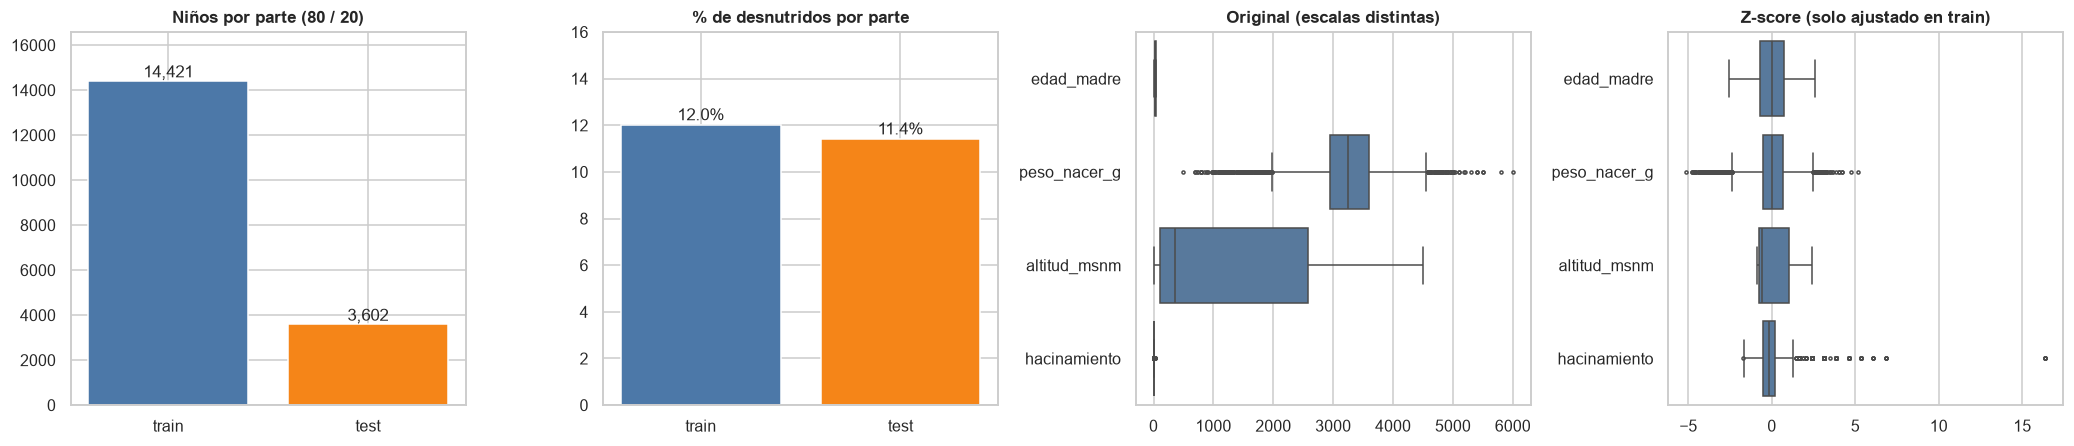

**Qué muestra:** izquierda, tamaño y prevalencia de *train* y *test*; derecha, cuatro variables antes y después de estandarizarse.  
**Lectura:** las dos partes se parecen (12.0 % y 11.4 % de desnutridos) y **no comparten ningún conglomerado** (0 en común). El escalado pone variables en gramos, años y metros en la misma escala, necesario para la regresión lineal; los árboles no lo necesitan. Imputación y escalado **no se guardan** en el CSV: viven dentro de los *Pipelines*.

In [13]:
resumen = limpio.groupby("particion").agg(niños=("caseid", "size"), conglomerados=("conglomerado", "nunique"),
                                          prevalencia=("desnutricion_cronica", "mean"), haz_medio=("haz", "mean"))
resumen = resumen.loc[["train", "test"]]
comun = set(limpio.loc[limpio.particion == "train", "conglomerado"]) & set(limpio.loc[limpio.particion == "test", "conglomerado"])

NUM_L = [c for c in FEAT_L if c not in CATEG_L]
train, test = limpio[limpio.particion == "train"], limpio[limpio.particion == "test"]
imp = SimpleImputer(strategy="median").fit(train[NUM_L])
ESC = ["edad_madre", "peso_nacer_g", "altitud_msnm", "hacinamiento"]
trn = pd.DataFrame(imp.transform(train[NUM_L]), columns=NUM_L)[ESC]
z = StandardScaler().fit(trn)
mm = MinMaxScaler().fit(trn)

fig, axes = plt.subplots(1, 4, figsize=(19, 4.2))
axes[0].bar(resumen.index, resumen["niños"], color=[AZUL, NARANJA])
for i, v in enumerate(resumen["niños"]):
    axes[0].text(i, v + 150, f"{v:,}", ha="center")
axes[0].set_ylim(0, resumen["niños"].max() * 1.15)
axes[0].set_title("Niños por parte (80 / 20)")
axes[1].bar(resumen.index, resumen["prevalencia"] * 100, color=[AZUL, NARANJA])
for i, v in enumerate(resumen["prevalencia"] * 100):
    axes[1].text(i, v + 0.2, f"{v:.1f}%", ha="center")
axes[1].set_ylim(0, 16)
axes[1].set_title("% de desnutridos por parte")
for ax, datos, tit in zip(axes[2:], [trn, pd.DataFrame(z.transform(trn), columns=ESC)], ["Original (escalas distintas)", "Z-score (solo ajustado en train)"]):
    sns.boxplot(data=datos, ax=ax, orient="h", color=AZUL, fliersize=2)
    ax.set_title(tit)
plt.tight_layout()
plt.show()
nota(f"**Qué muestra:** izquierda, tamaño y prevalencia de *train* y *test*; derecha, cuatro variables antes y después de estandarizarse.  \n"
     f"**Lectura:** las dos partes se parecen ({resumen.loc['train', 'prevalencia'] * 100:.1f} % y {resumen.loc['test', 'prevalencia'] * 100:.1f} % de desnutridos) y **no comparten ningún conglomerado** ({len(comun)} en común). "
     f"El escalado pone variables en gramos, años y metros en la misma escala, necesario para la regresión lineal; los árboles no lo necesitan. "
     f"Imputación y escalado **no se guardan** en el CSV: viven dentro de los *Pipelines*.")
assert len(comun) == 0

### Resumen de técnicas y estadísticos del tratamiento
Para ubicar rápido **cómo** se hizo cada cosa y **con qué números**: (A) técnica aplicada en cada paso, (B) estadísticos descriptivos antes y después, (C) valores atípicos con el método RIC y (D) valores vacíos.

#### A. Técnica aplicada en cada paso

In [14]:
def n_paso(paso):
    return f"{int(log.loc[log['paso'].astype(str) == paso, 'afectados'].iloc[0]):,}"


pd.DataFrame([
    ("1. Niños sin objetivo", "Filtro: quedarse con `haz` no vacío", "—", f"{n_paso('1')} niños eliminados"),
    ("2. Duplicados", "`duplicated()` sobre todas las columnas", "—", f"{n_paso('2')} (nada que quitar)"),
    ("3. Códigos especiales", "Reemplazo por `NaN` con la lista del diccionario, variable por variable", "9996-9999, 98, 9, 8", f"{n_paso('3')} valores"),
    ("4. Incoherencias", "Reglas lógicas de rango (p. ej. IMC 12-50)", "valor fuera de rango → NaN", f"{n_paso('4')} valores"),
    ("5. Atípicos", "Método del rango intercuartílico (RIC)", "[Q1 − 1.5·RIC, Q3 + 1.5·RIC]", "revisados; no se eliminan"),
    ("6. Vacunas según edad", "Regla por edad de la dosis", "NaN si edad < 6 m (DPT3, polio) o < 12 m (sarampión)", f"{n_paso('6')} valores"),
    ("7. Codificación", "Mapa manual (ordinal), 0/1 (binarias), `category` o One-Hot (nominales)", "sin LabelEncoder en ordinales", "8 variables recodificadas"),
    ("8. Valores faltantes", "**No se imputan en el CSV** (la mayoría 'no aplica'). En regresión lineal: imputación por **mediana** (numéricas) y **moda** (categóricas) dentro del Pipeline", "mediana/moda calculadas solo con *train*", "KNN u otros no hacen falta: XGBoost maneja `NaN`"),
    ("9. División", "`GroupShuffleSplit` por conglomerado, 80 / 20, semilla 42", "ningún conglomerado en ambos lados", "14 421 train / 3 602 test"),
    ("10. Escalado", "`StandardScaler` (Z-score) y `MinMaxScaler`, `fit` solo con *train*", "z = (x − media) / desviación", "solo para regresión lineal"),
], columns=["paso", "técnica", "regla o fórmula", "resultado"])

,paso,técnica,regla o fórmula,resultado
0,1. Niños sin objetivo,Filtro: quedarse con `haz` no vacío,—,818 niños eliminados
1,2. Duplicados,`duplicated()` sobre todas las columnas,—,0 (nada que quitar)
2,3. Códigos especiales,"Reemplazo por `NaN` con la lista del diccionario, variable por var...","9996-9999, 98, 9, 8","5,237 valores"
3,4. Incoherencias,Reglas lógicas de rango (p. ej. IMC 12-50),valor fuera de rango → NaN,21 valores
4,5. Atípicos,Método del rango intercuartílico (RIC),"[Q1 − 1.5·RIC, Q3 + 1.5·RIC]",revisados; no se eliminan
5,6. Vacunas según edad,Regla por edad de la dosis,"NaN si edad < 6 m (DPT3, polio) o < 12 m (sarampión)","5,652 valores"
6,7. Codificación,"Mapa manual (ordinal), 0/1 (binarias), `category` o One-Hot (nomin...",sin LabelEncoder en ordinales,8 variables recodificadas
7,8. Valores faltantes,**No se imputan en el CSV** (la mayoría 'no aplica'). En regresión...,mediana/moda calculadas solo con *train*,KNN u otros no hacen falta: XGBoost maneja `NaN`
8,9. División,"`GroupShuffleSplit` por conglomerado, 80 / 20, semilla 42",ningún conglomerado en ambos lados,14 421 train / 3 602 test
9,10. Escalado,"`StandardScaler` (Z-score) y `MinMaxScaler`, `fit` solo con *train*",z = (x − media) / desviación,solo para regresión lineal


#### B. Estadísticos descriptivos: crudo vs. limpio

In [15]:
VARS_D = ["haz", "peso_nacer_g", "talla_madre_x10", "imc_madre_x100", "n_controles_cred", "edad_madre", "altitud_msnm"]
filas = []
for v in VARS_D:
    for nombre, datos in [("crudo", crudo_ok), ("limpio", limpio)]:
        s = datos[v].dropna()
        filas.append({"variable": v, "datos": nombre, "n": len(s), "media": s.mean(), "mediana": s.median(), "desv. est.": s.std(),
                      "mínimo": s.min(), "máximo": s.max(), "asimetría": s.skew()})
desc = pd.DataFrame(filas).set_index(["variable", "datos"]).round(2)
desc

n    media  mediana  desv. est.   mínimo   máximo  asimetría
variable         datos                                                                   
haz              crudo   18023    -0.83    -0.83        1.03    -5.72     3.98      -0.06
                 limpio  18023    -0.83    -0.83        1.03    -5.72     3.98      -0.06
peso_nacer_g     crudo   18023  3410.78  3280.00     1158.63   500.00  9998.00       4.24
                 limpio  17595  3250.57  3255.00      542.48   500.00  6000.00      -0.34
talla_madre_x10  crudo   18023  1535.43  1526.00      266.10  1294.00  9999.00      30.35
                 limpio  18006  1527.44  1526.00       56.37  1294.00  1885.00       0.19
imc_madre_x100   crudo   18023  2846.21  2795.00      559.39  1453.00  9999.00       2.57
                 limpio  17987  2836.56  2794.00      505.92  1453.00  4998.00       0.58
n_controles_cred crudo   18023    16.73    16.00       10.80     0.00    98.00       3.85
                 limpio  17858    15.98    16.00        7.49     0.00    40.00       0.13
edad_madre       crudo   18023    30.89    31.00        6.96    13.00    49.00       0.05
                 limpio  18023    30.89    31.00        6.96    13.00    49.00       0.05
altitud_msnm     crudo   18023  1201.50   369.00     1377.38     1.00  4500.00       0.83
                 limpio  18023  1201.50   369.00     1377.38     1.00  4500.00       0.83

**Lectura:** donde había códigos especiales (`peso_nacer_g`, `talla_madre_x10`, `imc_madre_x100`, `n_controles_cred`) el **máximo** baja de ≈ 9 998 a un valor real, la **desviación** y la **asimetría** se reducen mucho y la **media** se acerca a la **mediana**. Las variables sin códigos (`haz`, `edad_madre`, `altitud_msnm`) no cambian, como debe ser.

#### C. Valores atípicos (RIC) en el dataset limpio

In [16]:
filas = []
for v in CONT:
    s = limpio[v].dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    ric = q3 - q1
    inf, sup = q1 - 1.5 * ric, q3 + 1.5 * ric
    n_out = int(((s < inf) | (s > sup)).sum())
    filas.append({"variable": v, "Q1": q1, "Q3": q3, "RIC": ric, "límite inferior": inf, "límite superior": sup, "atípicos": n_out, "%": round(100 * n_out / len(s), 1)})
pd.DataFrame(filas).set_index("variable").round(1)

,Q1,Q3,RIC,límite inferior,límite superior,atípicos,%
variable,,,,,,,
edad_madre,26.0,36.0,10.0,11.0,51.0,0,0.0
edad_primer_parto,18.0,24.0,6.0,9.0,33.0,484,2.7
peso_nacer_g,2940.0,3600.0,660.0,1950.0,4590.0,432,2.5
talla_madre_x10,1490.0,1564.0,74.0,1379.0,1675.0,203,1.1
imc_madre_x100,2482.0,3139.0,657.0,1496.5,4124.5,269,1.5
altitud_msnm,114.0,2584.0,2470.0,-3591.0,6289.0,0,0.0
hacinamiento,2.0,3.0,1.0,0.5,4.5,1542,8.6
intervalo_nac_previo_meses,42.0,103.0,61.0,-49.5,194.5,238,2.0


**Lectura:** los atípicos son pocos (0-9 %) y reales; se **conservan**. En `altitud_msnm` y `edad_madre` no hay ninguno.

#### D. Valores vacíos por variable (dataset limpio)

In [17]:
vac = pd.DataFrame({"vacíos": limpio[FEAT_L].isna().sum()})
vac["% del total"] = (100 * vac["vacíos"] / len(limpio)).round(1)
vac["motivo"] = ["No aplica (la pregunta no corresponde al niño)" if v in MOTIVO_NO_APLICA else "Falta el dato (no medido / no sabe)" for v in vac.index]
vac[vac["vacíos"] > 0].sort_values("vacíos", ascending=False)

,vacíos,% del total,motivo
lactancia_exclusiva_6m,8159,45.3,No aplica (la pregunta no corresponde al niño)
intervalo_nac_previo_meses,5884,32.6,No aplica (la pregunta no corresponde al niño)
vacuna_sarampion,3235,17.9,No aplica (la pregunta no corresponde al niño)
cloro_residual_agua,2494,13.8,Falta el dato (no medido / no sabe)
visitas_prenatales,1764,9.8,No aplica (la pregunta no corresponde al niño)
hierro_embarazo,1752,9.7,No aplica (la pregunta no corresponde al niño)
vacuna_dpt3,1576,8.7,No aplica (la pregunta no corresponde al niño)
vacuna_polio3,1491,8.3,No aplica (la pregunta no corresponde al niño)
severidad_anemia_nino,1388,7.7,Falta el dato (no medido / no sabe)
hierro_jarabe_7d,687,3.8,No aplica (la pregunta no corresponde al niño)


**Lectura:** los vacíos que **no aplican** (azul en el gráfico anterior) se dejan como `NaN`; los que **faltan** son pocos. Por eso no se imputa en el archivo guardado.

## 5. Antes vs. después

In [18]:
cod_c = int(sum(crudo[v].isin(c).sum() for v, c in CODIGOS.items()))
NOMBRE_L = {"sexo_nino": "nino_mujer", "area_residencia": "area_rural", "nivel_anemia_nino": "severidad_anemia_nino"}
cod_l = sum(int(limpio[NOMBRE_L.get(v, v)].isin(c).sum()) for v, c in CODIGOS.items() if v not in ("nivel_anemia_nino",))
cod_l += int(limpio["severidad_anemia_nino"].isin([9]).sum())
pd.DataFrame({
    "niños": [len(crudo), len(limpio)],
    "columnas": [crudo.shape[1], limpio.shape[1]],
    "variables predictoras": [len(FEAT_C), len(FEAT_L)],
    "códigos especiales sin convertir": [cod_c, cod_l],
    "niños sin objetivo": [int(crudo["haz"].isna().sum()), int(limpio["haz"].isna().sum())],
    "vacíos en las predictoras": [int(crudo[FEAT_C].isna().sum().sum()), int(limpio[FEAT_L].isna().sum().sum())],
}, index=["crudo", "limpio"])

,niños,columnas,variables predictoras,códigos especiales sin convertir,niños sin objetivo,vacíos en las predictoras
crudo,18841,50,42,6561,818,23887
limpio,18023,49,42,0,0,30249


**Lectura:** los códigos especiales pasan de miles a **cero** y desaparecen los niños sin objetivo. Los vacíos *aumentan*, y es lo correcto: antes los "no sabe" estaban escondidos como números y ahora se reconocen como lo que son.

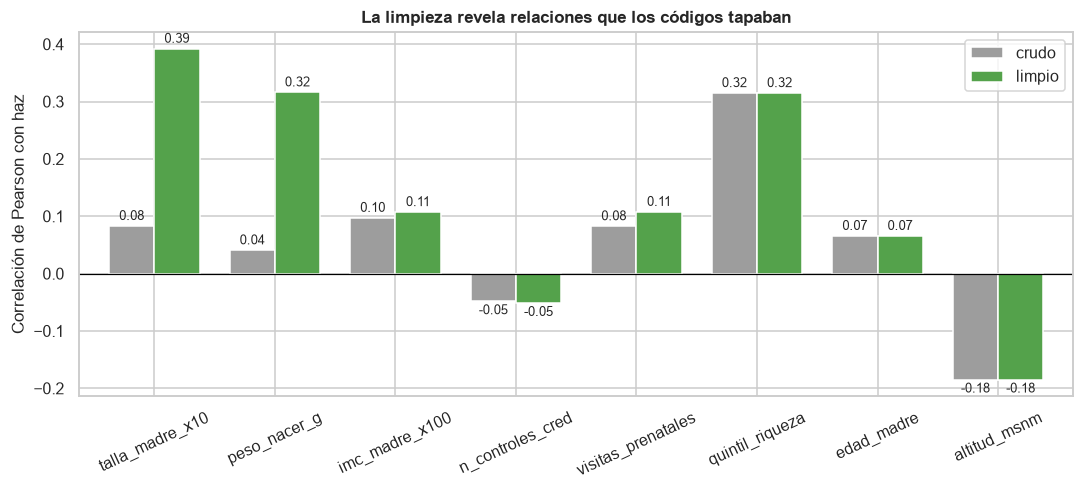

**Qué muestra:** qué tan fuerte es la relación lineal de cada variable con el puntaje Z, antes (gris) y después (verde) de limpiar.  
**Lectura:** el caso más claro es la **talla de la madre**: su correlación pasa de 0.08 a **0.39**, y la del peso al nacer sube de 0.04 a 0.32. Los códigos 9 999 y 9 998 *ocultaban* a los dos mejores predictores. Las variables sin códigos (riqueza, edad de la madre, altitud) no cambian, como debe ser.

In [19]:
# Efecto sobre la relación con el objetivo: correlación de Pearson con el puntaje Z, antes y después
vars_c = ["talla_madre_x10", "peso_nacer_g", "imc_madre_x100", "n_controles_cred", "visitas_prenatales", "quintil_riqueza", "edad_madre", "altitud_msnm"]
cor = pd.DataFrame({"crudo": [crudo_ok[v].corr(crudo_ok["haz"]) for v in vars_c],
                    "limpio": [limpio[v].corr(limpio["haz"]) for v in vars_c]}, index=vars_c)
fig, ax = plt.subplots(figsize=(10, 4.6))
cor.plot.bar(ax=ax, color=[GRIS, VERDE], rot=25, width=0.75)
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f", fontsize=8.5, padding=2)
ax.axhline(0, color="black", lw=0.8)
ax.set_ylabel("Correlación de Pearson con haz")
ax.set_title("La limpieza revela relaciones que los códigos tapaban")
ax.legend(title="")
plt.tight_layout()
plt.show()
mejora_talla = cor.loc["talla_madre_x10"]
nota(f"**Qué muestra:** qué tan fuerte es la relación lineal de cada variable con el puntaje Z, antes (gris) y después (verde) de limpiar.  \n"
     f"**Lectura:** el caso más claro es la **talla de la madre**: su correlación pasa de {mejora_talla['crudo']:.2f} a **{mejora_talla['limpio']:.2f}**, y la del peso al nacer sube de {cor.loc['peso_nacer_g', 'crudo']:.2f} a {cor.loc['peso_nacer_g', 'limpio']:.2f}. "
     f"Los códigos 9 999 y 9 998 *ocultaban* a los dos mejores predictores. Las variables sin códigos (riqueza, edad de la madre, altitud) no cambian, como debe ser.")

## 6. Exploración con datos limpios
Con el dataset limpio se repiten los análisis clave. La partición (`particion`) permite calcularlos sobre todo el conjunto o solo sobre *train*; aquí es solo exploración.

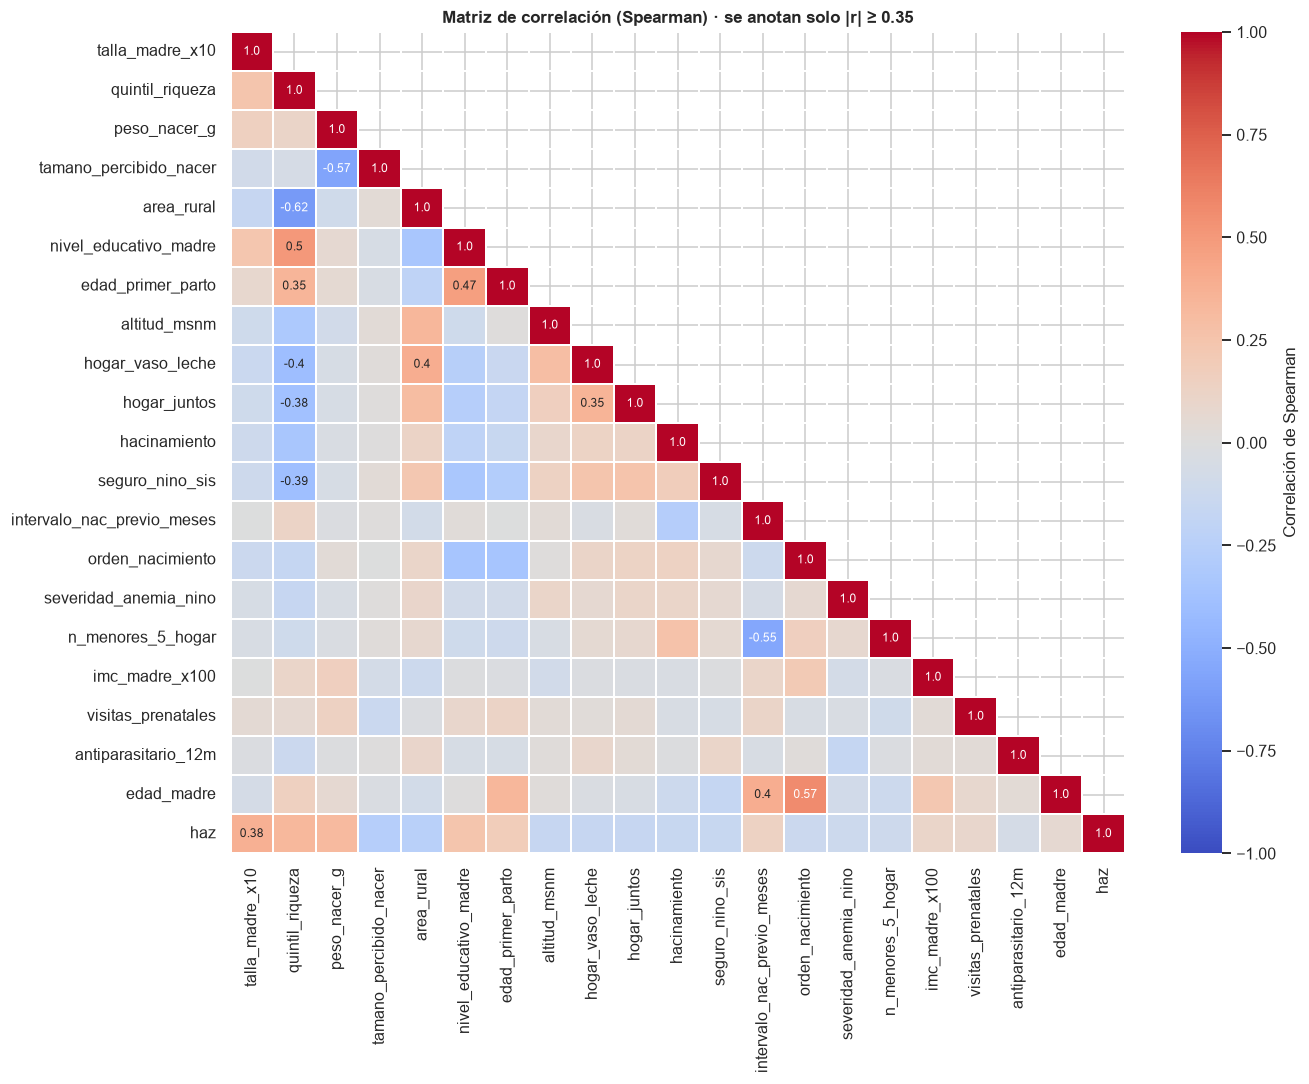

**Cómo leerlo:** cada celda es la correlación entre dos variables (rojo = suben juntas, azul = una sube cuando la otra baja). La última fila es la relación con el `haz`.  
**Lectura:** las variables más ligadas al `haz` son `talla_madre_x10` (+0.38), `quintil_riqueza` (+0.33) y `peso_nacer_g` (+0.31). Entre predictoras, el par más fuerte es riqueza con área rural (≈ −0.6): hay algo de redundancia, que no afecta a los árboles.

In [20]:
corr_s = limpio[NUM_L].corrwith(limpio["haz"], method="spearman")
top = corr_s.reindex(corr_s.abs().sort_values(ascending=False).index).head(20)
vars_mapa = top.index.tolist() + ["haz"]
c2 = limpio[vars_mapa].corr(method="spearman")
mascara = np.triu(np.ones_like(c2, dtype=bool), k=1)
anot = np.where(c2.abs() >= 0.35, c2.round(2).astype(str), "")

fig, ax = plt.subplots(figsize=(12.5, 10))
sns.heatmap(c2, mask=mascara, cmap="coolwarm", vmin=-1, vmax=1, center=0, annot=anot, fmt="", annot_kws={"size": 8},
            linewidths=0.3, cbar_kws={"label": "Correlación de Spearman"}, ax=ax)
ax.set_title("Matriz de correlación (Spearman) · se anotan solo |r| ≥ 0.35")
plt.tight_layout()
plt.show()
nota(f"**Cómo leerlo:** cada celda es la correlación entre dos variables (rojo = suben juntas, azul = una sube cuando la otra baja). La última fila es la relación con el `haz`.  \n"
     f"**Lectura:** las variables más ligadas al `haz` son `{top.index[0]}` ({top.iloc[0]:+.2f}), `{top.index[1]}` ({top.iloc[1]:+.2f}) y `{top.index[2]}` ({top.iloc[2]:+.2f}). "
     f"Entre predictoras, el par más fuerte es riqueza con área rural (≈ −0.6): hay algo de redundancia, que no afecta a los árboles.")

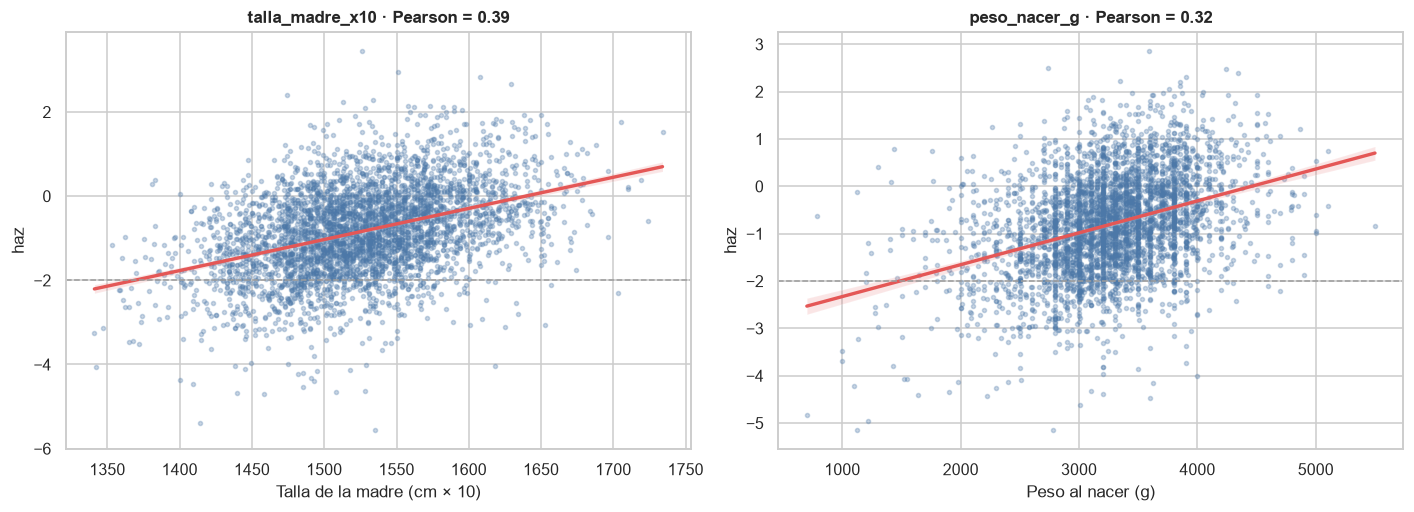

**Cómo leerlo:** cada punto es un niño (4 000 al azar); la recta roja es la tendencia; los puntos bajo la línea gris tienen desnutrición crónica.  
**Lectura:** ahora sí se ve la relación esperada: **madres más altas y bebés más pesados tienen niños con mayor puntaje Z**. En los datos crudos esta nube quedaba aplastada contra un extremo por los códigos.

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, (var, nombre) in zip(axes, [("talla_madre_x10", "Talla de la madre (cm × 10)"), ("peso_nacer_g", "Peso al nacer (g)")]):
    m = limpio[[var, "haz"]].dropna().sample(4000, random_state=42)
    sns.regplot(data=m, x=var, y="haz", ax=ax, scatter_kws={"s": 7, "alpha": 0.3, "color": AZUL}, line_kws={"color": ROJO, "lw": 2.2})
    ax.axhline(-2, color=GRIS, ls="--", lw=1)
    ax.set_xlabel(nombre)
    ax.set_ylabel("haz")
    ax.set_title(f"{var} · Pearson = {limpio[var].corr(limpio['haz']):.2f}")
plt.tight_layout()
plt.show()
nota("**Cómo leerlo:** cada punto es un niño (4 000 al azar); la recta roja es la tendencia; los puntos bajo la línea gris tienen desnutrición crónica.  \n**Lectura:** ahora sí se ve la relación esperada: **madres más altas y bebés más pesados tienen niños con mayor puntaje Z**. En los datos crudos esta nube quedaba aplastada contra un extremo por los códigos.")

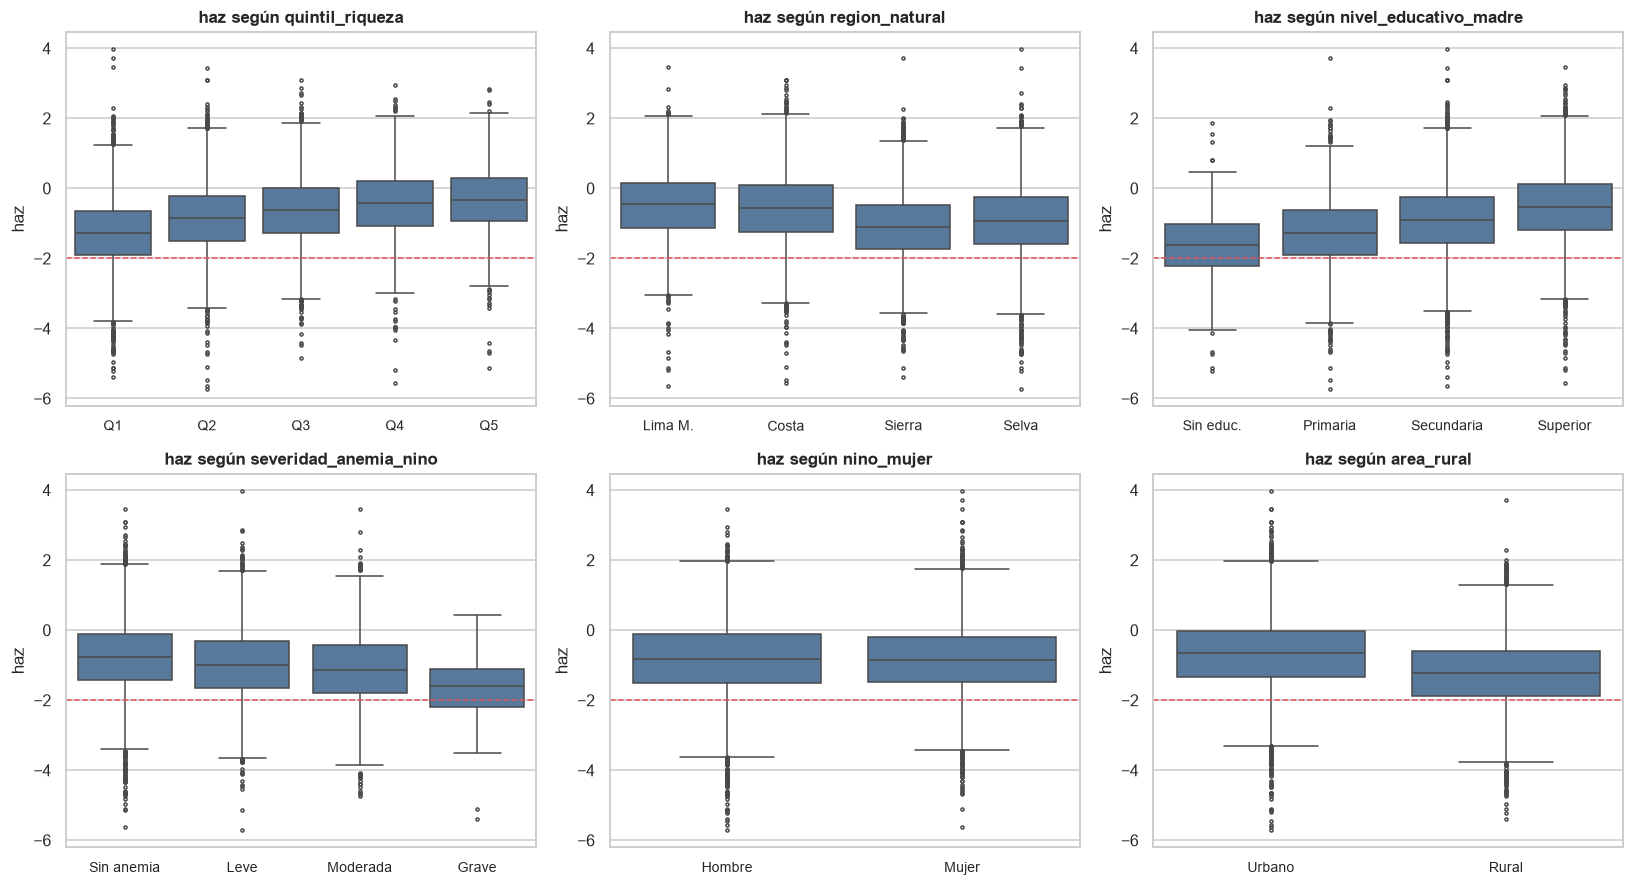

**Cómo leerlo:** una caja por grupo; la línea central es la mediana del puntaje Z y la roja punteada es el umbral de desnutrición (−2).  
**Lectura:** el puntaje Z **sube** con la riqueza y la educación de la madre, es **menor** en Sierra, Selva y zonas rurales, y **baja** con la gravedad de la anemia; el sexo casi no separa las cajas.

In [22]:
ETQ_L = {"quintil_riqueza": {1: "Q1", 2: "Q2", 3: "Q3", 4: "Q4", 5: "Q5"}, "region_natural": {1: "Lima M.", 2: "Costa", 3: "Sierra", 4: "Selva"},
         "nivel_educativo_madre": {0: "Sin educ.", 1: "Primaria", 2: "Secundaria", 3: "Superior"},
         "severidad_anemia_nino": {0: "Sin anemia", 1: "Leve", 2: "Moderada", 3: "Grave"}, "nino_mujer": {0: "Hombre", 1: "Mujer"}, "area_rural": {0: "Urbano", 1: "Rural"}}
fig, axes = plt.subplots(2, 3, figsize=(15, 8.2))
for ax, var in zip(axes.ravel(), ETQ_L):
    orden = sorted(limpio[var].dropna().unique())
    sns.boxplot(data=limpio, x=var, y="haz", order=orden, ax=ax, color=AZUL, fliersize=2)
    ax.set_xticklabels([ETQ_L[var][int(c)] for c in orden], fontsize=9)
    ax.axhline(-2, color=ROJO, ls="--", lw=1)
    ax.set_xlabel("")
    ax.set_title(f"haz según {var}")
plt.tight_layout()
plt.show()
nota("**Cómo leerlo:** una caja por grupo; la línea central es la mediana del puntaje Z y la roja punteada es el umbral de desnutrición (−2).  \n**Lectura:** el puntaje Z **sube** con la riqueza y la educación de la madre, es **menor** en Sierra, Selva y zonas rurales, y **baja** con la gravedad de la anemia; el sexo casi no separa las cajas.")

## 7. Modelos de base y efecto de la limpieza (Semana 05)
Se predice el puntaje Z con **regresión lineal** y **Random Forest** (con un modelo de referencia que siempre predice la media). Mismos niños, misma partición por conglomerado; imputación por mediana/moda y *One-Hot* dentro del *Pipeline* (ajustados solo con *train*). Métricas: **MAE, RMSE, R²** (Semana 05).

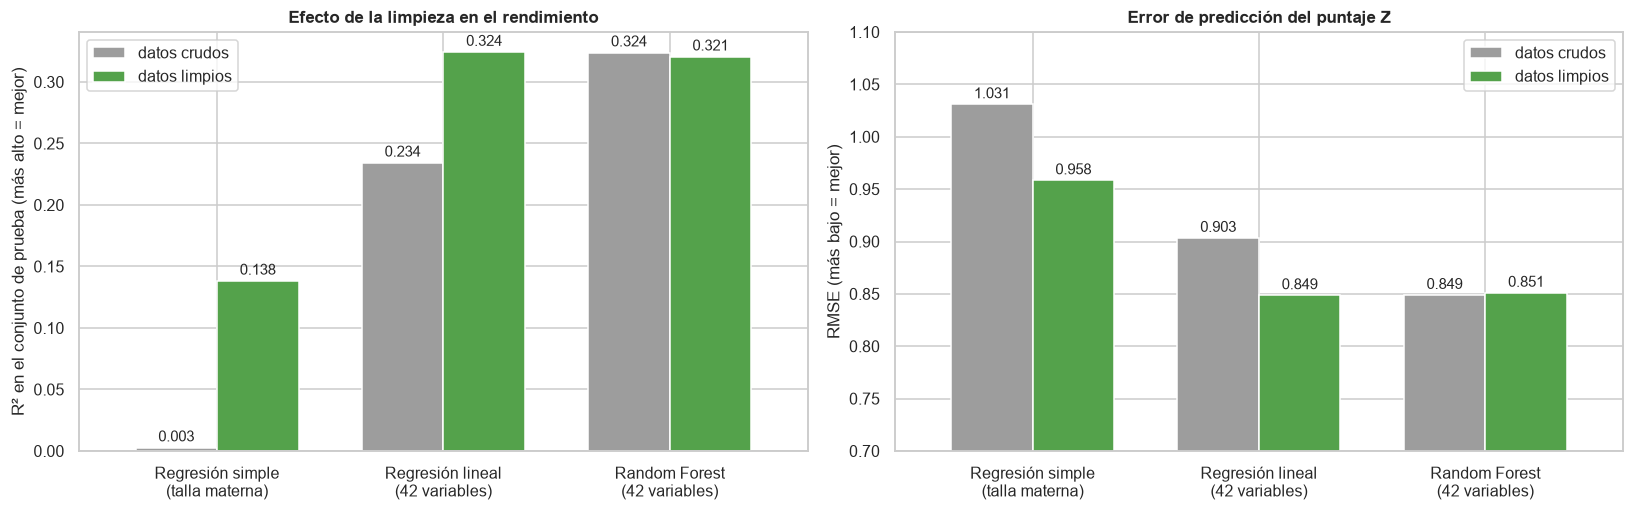

,R² crudo,R² limpio,RMSE crudo,RMSE limpio,MAE crudo,MAE limpio
Regresión simple (talla materna),0.003,0.138,1.031,0.958,0.809,0.755
Regresión lineal (42 variables),0.234,0.324,0.903,0.849,0.709,0.669
Random Forest (42 variables),0.324,0.321,0.849,0.851,0.668,0.670


In [23]:
mask_test = (limpio["particion"] == "test").values


def correr(datos, feats, categ):
    X, y = datos[feats], datos["haz"]
    Xtr, Xte, ytr, yte = X[~mask_test], X[mask_test], y[~mask_test], y[mask_test]
    num = [c for c in feats if c not in categ]
    prep = ColumnTransformer([("num", SimpleImputer(strategy="median"), num),
                              ("cat", Pipeline([("i", SimpleImputer(strategy="most_frequent")), ("o", OneHotEncoder(handle_unknown="ignore"))]), categ)])
    res, preds = {}, {}
    simple = Pipeline([("i", SimpleImputer(strategy="median")), ("m", LinearRegression())]).fit(Xtr[["talla_madre_x10"]], ytr)
    preds["Regresión simple\n(talla materna)"] = simple.predict(Xte[["talla_madre_x10"]])
    modelos = {"Regresión lineal\n(42 variables)": LinearRegression(),
               "Random Forest\n(42 variables)": RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)}
    pipes = {}
    for nombre, m in modelos.items():
        pipes[nombre] = Pipeline([("p", prep), ("m", m)]).fit(Xtr, ytr)
        preds[nombre] = pipes[nombre].predict(Xte)
    for nombre, p in preds.items():
        res[nombre] = {"MAE": mean_absolute_error(yte, p), "RMSE": float(np.sqrt(mean_squared_error(yte, p))), "R²": r2_score(yte, p)}
    return pd.DataFrame(res).T, preds, yte, pipes


res_c, _, _, _ = correr(crudo_ok, FEAT_C, CATEG_C)
res_l, preds_l, y_te, pipes_l = correr(limpio, FEAT_L, CATEG_L)
comp = pd.DataFrame({"R² crudo": res_c["R²"], "R² limpio": res_l["R²"], "RMSE crudo": res_c["RMSE"], "RMSE limpio": res_l["RMSE"],
                     "MAE crudo": res_c["MAE"], "MAE limpio": res_l["MAE"]})
comp.index = [i.replace("\n", " ") for i in comp.index]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
r2 = pd.DataFrame({"datos crudos": res_c["R²"], "datos limpios": res_l["R²"]})
r2.plot.bar(ax=axes[0], color=[GRIS, VERDE], rot=0, width=0.72)
for c in axes[0].containers:
    axes[0].bar_label(c, fmt="%.3f", fontsize=9.5, padding=2)
axes[0].set_ylabel("R² en el conjunto de prueba (más alto = mejor)")
axes[0].set_title("Efecto de la limpieza en el rendimiento")
axes[0].legend(title="")
rm = pd.DataFrame({"datos crudos": res_c["RMSE"], "datos limpios": res_l["RMSE"]})
rm.plot.bar(ax=axes[1], color=[GRIS, VERDE], rot=0, width=0.72)
for c in axes[1].containers:
    axes[1].bar_label(c, fmt="%.3f", fontsize=9.5, padding=2)
axes[1].set_ylim(0.7, 1.1)
axes[1].set_ylabel("RMSE (más bajo = mejor)")
axes[1].set_title("Error de predicción del puntaje Z")
axes[1].legend(title="")
plt.tight_layout()
plt.show()
comp.round(3)

In [24]:
s_c, s_l = res_c.iloc[0]["R²"], res_l.iloc[0]["R²"]
nota(f"**Qué muestra:** R² (proporción de la variación del puntaje Z que el modelo explica; 0 = nada, 1 = todo) y RMSE (error típico en unidades de puntaje Z), con datos crudos (gris) y limpios (verde).  \n"
     f"**Lectura:** la **regresión simple** con la talla de la madre pasa de R² = {s_c:.3f} a **{s_l:.3f}**: sin el código 9999 la variable por fin funciona. "
     f"La **regresión lineal** con 42 variables sube de {res_c.iloc[1]['R²']:.3f} a **{res_l.iloc[1]['R²']:.3f}** y alcanza al **Random Forest** ({res_l.iloc[2]['R²']:.3f}), que ya toleraba los códigos y casi no cambia. "
     f"Un RMSE de ≈ {res_l.iloc[2]['RMSE']:.2f} frente a ≈ 1.03 de predecir siempre la media confirma que hay señal real. "
     f"**Conclusión:** la limpieza beneficia sobre todo a los modelos lineales; para XGBoost aporta datos **confiables e interpretables**.")

**Qué muestra:** R² (proporción de la variación del puntaje Z que el modelo explica; 0 = nada, 1 = todo) y RMSE (error típico en unidades de puntaje Z), con datos crudos (gris) y limpios (verde).  
**Lectura:** la **regresión simple** con la talla de la madre pasa de R² = 0.003 a **0.138**: sin el código 9999 la variable por fin funciona. La **regresión lineal** con 42 variables sube de 0.234 a **0.324** y alcanza al **Random Forest** (0.321), que ya toleraba los códigos y casi no cambia. Un RMSE de ≈ 0.85 frente a ≈ 1.03 de predecir siempre la media confirma que hay señal real. **Conclusión:** la limpieza beneficia sobre todo a los modelos lineales; para XGBoost aporta datos **confiables e interpretables**.

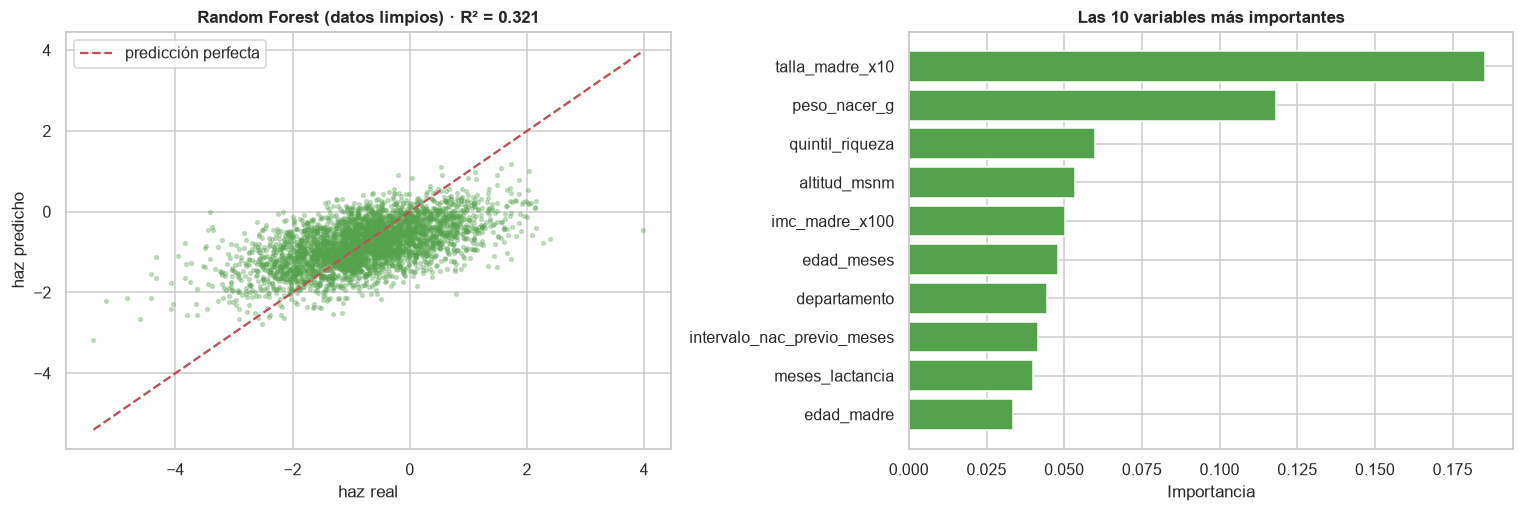

**Cómo leerlo:** izquierda, cada punto es un niño de la prueba: si el modelo fuera perfecto, caería sobre la línea roja. Derecha, qué variables usa más el bosque.  
**Lectura:** la nube sigue la diagonal (hay relación), aunque más aplanada, porque el modelo tiende a predecir cerca de la media y subestima los extremos: es normal con R² moderado. Las variables más importantes son `talla_madre_x10`, `peso_nacer_g` y `quintil_riqueza`, coherentes con la exploración.

In [25]:
rf = pipes_l["Random Forest\n(42 variables)"]
nombres = rf.named_steps["p"].get_feature_names_out()
imp = pd.Series(rf.named_steps["m"].feature_importances_, index=nombres)
base = imp.index.to_series().map(lambda n: next((c for c in CATEG_L if n.split("__", 1)[1].startswith(c + "_")), n.split("__", 1)[1]))
top = imp.groupby(base).sum().sort_values(ascending=False).head(10)[::-1]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
p = preds_l["Random Forest\n(42 variables)"]
axes[0].scatter(y_te, p, s=6, alpha=0.3, color=VERDE)
lim = [min(y_te.min(), p.min()), max(y_te.max(), p.max())]
axes[0].plot(lim, lim, "r--", lw=1.5, label="predicción perfecta")
axes[0].set_xlabel("haz real")
axes[0].set_ylabel("haz predicho")
axes[0].set_title(f"Random Forest (datos limpios) · R² = {r2_score(y_te, p):.3f}")
axes[0].legend()
axes[1].barh(top.index, top.values, color=VERDE)
axes[1].set_xlabel("Importancia")
axes[1].set_title("Las 10 variables más importantes")
plt.tight_layout()
plt.show()
nota(f"**Cómo leerlo:** izquierda, cada punto es un niño de la prueba: si el modelo fuera perfecto, caería sobre la línea roja. Derecha, qué variables usa más el bosque.  \n"
     f"**Lectura:** la nube sigue la diagonal (hay relación), aunque más aplanada, porque el modelo tiende a predecir cerca de la media y subestima los extremos: es normal con R² moderado. "
     f"Las variables más importantes son `{top.index[-1]}`, `{top.index[-2]}` y `{top.index[-3]}`, coherentes con la exploración.")

### Optimización: función de error y descenso de gradiente (Semana 03)
Entrenar es **buscar los parámetros que minimizan el error**. Con `quintil_riqueza` (estandarizada) como único predictor del `haz`:

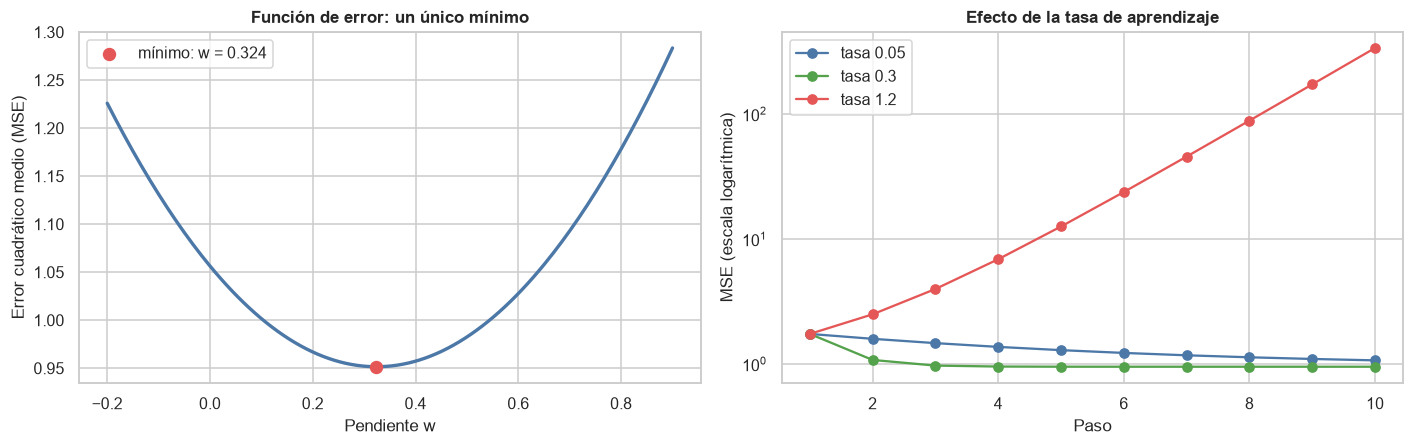

**Lectura:** el error forma una "U" con un único mínimo. Con tasa 0.3 el descenso llega al mismo resultado que scikit-learn (w = 0.324 frente a 0.324); con 0.05 es demasiado lento y con 1.2 **diverge**. En XGBoost este parámetro es `learning_rate`.

In [26]:
x = ((limpio["quintil_riqueza"] - limpio["quintil_riqueza"].mean()) / limpio["quintil_riqueza"].std()).values
yv, n = limpio["haz"].values, len(limpio)
sk = LinearRegression().fit(x.reshape(-1, 1), yv)
w_opt, b_opt = sk.coef_[0], sk.intercept_


def descenso(tasa, pasos=10):
    w = b = 0.0
    h = []
    for _ in range(pasos):
        e = w * x + b - yv
        h.append(np.mean(e ** 2))
        w, b = w - tasa * (2 / n) * np.sum(e * x), b - tasa * (2 / n) * np.sum(e)
    return h, w, b


fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
ws = np.linspace(-0.2, 0.9, 200)
axes[0].plot(ws, [np.mean((w * x + b_opt - yv) ** 2) for w in ws], color=AZUL, lw=2.2)
axes[0].scatter([w_opt], [np.mean((w_opt * x + b_opt - yv) ** 2)], color=ROJO, s=60, zorder=5, label=f"mínimo: w = {w_opt:.3f}")
axes[0].set_xlabel("Pendiente w")
axes[0].set_ylabel("Error cuadrático medio (MSE)")
axes[0].set_title("Función de error: un único mínimo")
axes[0].legend()
for t, col in zip([0.05, 0.3, 1.2], [AZUL, VERDE, ROJO]):
    axes[1].plot(range(1, 11), descenso(t)[0], marker="o", color=col, label=f"tasa {t}")
axes[1].set_yscale("log")
axes[1].set_xlabel("Paso")
axes[1].set_ylabel("MSE (escala logarítmica)")
axes[1].set_title("Efecto de la tasa de aprendizaje")
axes[1].legend()
plt.tight_layout()
plt.show()
_, w3, b3 = descenso(0.3)
nota(f"**Lectura:** el error forma una \"U\" con un único mínimo. Con tasa 0.3 el descenso llega al mismo resultado que scikit-learn (w = {w3:.3f} frente a {w_opt:.3f}); con 0.05 es demasiado lento y con 1.2 **diverge**. En XGBoost este parámetro es `learning_rate`.")

## 8. Conclusiones y archivos

In [27]:
pd.DataFrame([
    ("Eliminar niños sin objetivo", "Sin respuesta no se puede entrenar ni evaluar", "818 niños (4.3 %)"),
    ("Códigos especiales → vacío", "Un 9998 no es un peso; distorsionaba medias, correlaciones y modelos", f"5 237 valores; talla materna r: {mejora_talla[chr(99)+chr(114)+chr(117)+chr(100)+chr(111)]:.2f} → {mejora_talla[chr(108)+chr(105)+chr(109)+chr(112)+chr(105)+chr(111)]:.2f}"),
    ("Recodificar 94 y las vacunas", "Para que cada número signifique lo que parece", "3 variables de vacunas + lactancia"),
    ("Vacunas según la edad", "\"Aún no corresponde\" no es \"no vacunado\"", "5 652 valores"),
    ("Conservar atípicos y vacíos por diseño", "Son reales o no aplican; rellenarlos inventaría datos", "0 eliminados"),
    ("Codificar binarias, ordinales y nominales", "Evitar escalas falsas (sin LabelEncoder en ordinales)", "8 variables recodificadas"),
    ("Partición por conglomerado", "Niños de un mismo conglomerado se parecen: evitar fuga", "14 421 train / 3 602 test"),
    ("Imputar y escalar solo con train", "Evitar *data leakage*", "dentro de los Pipelines"),
], columns=["decisión", "por qué", "evidencia"])

,decisión,por qué,evidencia
0,Eliminar niños sin objetivo,Sin respuesta no se puede entrenar ni evaluar,818 niños (4.3 %)
1,Códigos especiales → vacío,"Un 9998 no es un peso; distorsionaba medias, correlaciones y modelos",5 237 valores; talla materna r: 0.08 → 0.39
2,Recodificar 94 y las vacunas,Para que cada número signifique lo que parece,3 variables de vacunas + lactancia
3,Vacunas según la edad,"""Aún no corresponde"" no es ""no vacunado""",5 652 valores
4,Conservar atípicos y vacíos por diseño,Son reales o no aplican; rellenarlos inventaría datos,0 eliminados
5,"Codificar binarias, ordinales y nominales",Evitar escalas falsas (sin LabelEncoder en ordinales),8 variables recodificadas
6,Partición por conglomerado,Niños de un mismo conglomerado se parecen: evitar fuga,14 421 train / 3 602 test
7,Imputar y escalar solo con train,Evitar *data leakage*,dentro de los Pipelines


### Archivos generados (carpeta `3 datos_procesados`)
| Archivo | Contenido |
|---|---|
| `dataset_integrado_crudo.csv` | 18 841 niños × 50 columnas, **sin limpiar** (se conserva para seguir analizando) |
| `diccionario_variables.csv` | nombre, rol, tipo, tabla y código ENDES de cada columna cruda |
| **`dataset_limpio.csv`** | **18 023 niños × 49 columnas**, listo para modelar; incluye `particion` (train/test por conglomerado) |
| `diccionario_limpio.csv` | qué tratamiento recibió cada variable, con su nombre crudo y limpio |
| `registro_limpieza.csv` | los pasos de limpieza y cuántos valores afectó cada uno |

### Cómo se usa el dataset limpio
```python
limpio = pd.read_csv("dataset_limpio.csv")
feats  = dic_limpio.query("rol == 'feature'").nombre        # 42 variables predictoras
train  = limpio[limpio.particion == "train"]                # 14 421 niños
test   = limpio[limpio.particion == "test"]                 #  3 602 niños
# XGBoost: columnas nominales como category, scale_pos_weight por el desbalance, AUC-PR / recall / F1
```

### Temas de las guías cubiertos
| Guía | Tema | Dónde se ve |
|---|---|---|
| S03 | Estadísticos descriptivos, correlación | secciones 3, 5, 6 |
| S03 | Función de error y descenso de gradiente; tipos de problema | sección 1 y final de 7 |
| S04 | Estructura y tipos de variable; diagnóstico de calidad | secciones 2 y 3 |
| S04 | Faltantes, duplicados, inconsistencias, atípicos (reglas y RIC) | secciones 3 y 4 |
| S04 | Codificación (ordinal, binaria, nominal) | sección 4, paso 7 |
| S04 | Normalización y estandarización; *train/test* sin fuga | sección 4, pasos 9 y 10 |
| S05 | Regresión simple y múltiple, MAE/RMSE/R², Pipeline, Random Forest | sección 7 |

### Siguiente paso
Entrenar **XGBoost** sobre `dataset_limpio.csv` (clasificación de `desnutricion_cronica`), con `scale_pos_weight`, evaluación por AUC-PR, recall y F1, e interpretación con importancia por ganancia y SHAP.